# JRT results: supplementary tables and figures

Display notebook for the manuscript's Supplementary Material. Like `02_jrt_results.ipynb`
it fits nothing: it shows the outputs of the R pipeline in `../R/` as labelled tables
and figures. Sections follow the supplement of the manuscript. Re-execute after every
pipeline run.

In [1]:
from jrt_display import *

## 1. Data and rater exclusion

In [2]:
#| label: tbl-excluded-raters
#| tbl-cap: "Raters excluded from all analyses because they gave fewer than 15 ratings."
show_table("excluded_raters.csv")

| Rater   | Ratings by rater   | Reason                |
|:--------|:-------------------|:----------------------|
| R20     | 13                 | fewer than 15 ratings |
| R21     | 9                  | fewer than 15 ratings |
| R22     | 2                  | fewer than 15 ratings |
| R28     | 7                  | fewer than 15 ratings |
| R29     | 1                  | fewer than 15 ratings |

**Sensitivity to the rater exclusion.** The GRM refitted on all raters, including those with fewer than 15 ratings, compared with the final GRM: reliability, agreement of the product scores, and the discriminations of the common raters.

In [3]:
#| label: tbl-sensitivity-rater-exclusion
#| tbl-cap: "Sensitivity of the GRM results to excluding raters with fewer than 15 ratings: final data versus all raters."
show_table("sensitivity_rater_exclusion.csv", digits=5)

| Quantity                         | Final data   | All raters                                            | Note                                           |
|:---------------------------------|:-------------|:------------------------------------------------------|:-----------------------------------------------|
| n raters                         | 24           | 28                                                    | –                                              |
| n ratings                        | 9,471        | 9,502                                                 | –                                              |
| n products                       | 3,840        | 3,841                                                 | –                                              |
| excluded raters                  | –            | R20;R21;R22;R28;R29;R29 (one category, not estimable) | –                                              |
| empirical marginal reliability   | 0.68439      | 0.68385                                               | Var(theta)/(Var(theta)+mean(PSD^2))            |
| model based marginal reliability | 0.96799      | 0.97062                                               | mirt::marginal rxx (hypothetical full panel)   |
| theta pearson common products    | 0.99993      | –                                                     | all-raters vs final GRM, 3,840 common products |
| theta spearman common products   | 0.99993      | –                                                     | all-raters vs final GRM, 3,840 common products |
| theta mean abs diff              | 0.00205      | –                                                     | all-raters vs final GRM, 3,840 common products |
| theta max abs diff               | 0.36746      | –                                                     | all-raters vs final GRM, 3,840 common products |
| share products changing quintile | 0.00156      | –                                                     | all-raters vs final GRM, 3,840 common products |
| a max abs diff common raters     | 0.19029      | –                                                     | all-raters vs final GRM, 24 common raters      |
| a pearson common raters          | 0.99729      | –                                                     | all-raters vs final GRM, 24 common raters      |

**Ratings per product.** Number of products by the number of ratings they received.

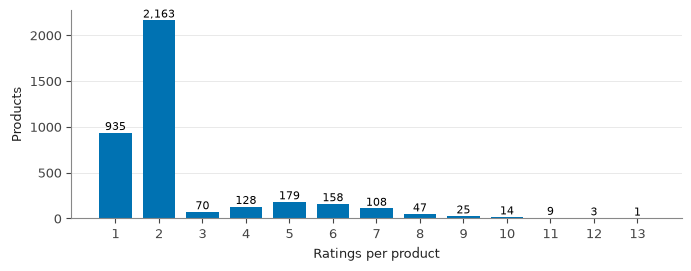

In [4]:
#| label: fig-design-ratings-per-product
#| fig-cap: "Number of products by number of ratings received."
_rpp = read_res("design_summary_ratings_per_product.csv")
with plt.rc_context(PLOT_STYLE):
    _f, _ax = plt.subplots(figsize=(7, 2.8))
    _ax.bar(_rpp["n_ratings"], _rpp["n_products"], color=C["blue"], width=0.75)
    for _x, _y in zip(_rpp["n_ratings"], _rpp["n_products"]):
        _ax.text(_x, _y, f"{_y:,}", ha="center", va="bottom", fontsize=8)
    _ax.set_xticks(_rpp["n_ratings"])
    _ax.set_xlabel("Ratings per product")
    _ax.set_ylabel("Products")
    _ax.grid(axis="x", visible=False)
    _f.tight_layout()
    plt.show()

**Category use.** How often each rater used each of the 7 categories. Raters who never use a category get fewer thresholds in mirt, because mirt only models the categories a rater actually used.

In [5]:
#| label: tbl-category-usage
#| tbl-cap: "Category use per rater (counts of ratings 1-7). Unused categories at the ends of the scale reduce the number of thresholds of a rater; an unused category inside the observed range (internal gap) makes that rater's thresholds incomparable with those of other raters."
show_table("category_usage.csv", lambda d: d[["rater_id"] + [c for c in d if c.startswith("cat_")] + ["n_ratings", "missing_categories", "internal_gap"]])

| Rater   | Category 1   | Category 2   | Category 3   | Category 4   | Category 5   | Category 6   | Category 7   | Ratings by rater   | Missing categories   | Internal gap   |
|:--------|:-------------|:-------------|:-------------|:-------------|:-------------|:-------------|:-------------|:-------------------|:---------------------|:---------------|
| R01     | 337          | 461          | 259          | 87           | 24           | 6            | 0            | 1,174              | 7                    | False          |
| R02     | 241          | 179          | 124          | 126          | 91           | 67           | 45           | 873                | –                    | False          |
| R03     | 161          | 182          | 185          | 82           | 88           | 22           | 0            | 720                | 7                    | False          |
| R04     | 164          | 164          | 90           | 69           | 92           | 36           | 5            | 620                | –                    | False          |
| R05     | 159          | 190          | 102          | 90           | 50           | 30           | 12           | 633                | –                    | False          |
| R06     | 301          | 113          | 57           | 34           | 9            | 6            | 0            | 520                | 7                    | False          |
| R07     | 183          | 152          | 96           | 61           | 36           | 17           | 2            | 547                | –                    | False          |
| R08     | 101          | 127          | 106          | 91           | 60           | 30           | 7            | 522                | –                    | False          |
| R09     | 63           | 62           | 72           | 60           | 66           | 55           | 22           | 400                | –                    | False          |
| R10     | 25           | 156          | 76           | 64           | 47           | 13           | 2            | 383                | –                    | False          |
| R11     | 127          | 118          | 51           | 31           | 32           | 9            | 1            | 369                | –                    | False          |
| R12     | 11           | 48           | 90           | 77           | 27           | 10           | 1            | 264                | –                    | False          |
| R13     | 4            | 35           | 68           | 91           | 44           | 11           | 1            | 254                | –                    | False          |
| R14     | 135          | 80           | 48           | 42           | 14           | 6            | 2            | 327                | –                    | False          |
| R15     | 7            | 22           | 11           | 9            | 13           | 9            | 2            | 73                 | –                    | False          |
| R16     | 36           | 76           | 103          | 70           | 31           | 9            | 3            | 328                | –                    | False          |
| R17     | 25           | 10           | 9            | 4            | 4            | 0            | 0            | 52                 | 6;7                  | False          |
| R18     | 1            | 8            | 14           | 12           | 16           | 4            | 0            | 55                 | 7                    | False          |
| R19     | 17           | 37           | 40           | 55           | 50           | 35           | 16           | 250                | –                    | False          |
| R23     | 65           | 99           | 151          | 117          | 100          | 40           | 17           | 589                | –                    | False          |
| R24     | 22           | 54           | 49           | 55           | 67           | 35           | 5            | 287                | –                    | False          |
| R25     | 18           | 30           | 39           | 34           | 15           | 2            | 0            | 138                | 7                    | False          |
| R26     | 5            | 13           | 12           | 10           | 5            | 1            | 0            | 46                 | 7                    | False          |
| R27     | 21           | 12           | 6            | 7            | 0            | 1            | 0            | 47                 | 5;7                  | True           |

## 2. Estimation and fit of the graded response model

**Estimation.** The GRM is fitted by marginal maximum likelihood in `mirt` (Chalmers, 2012). The table shows whether estimation converged and gives the information criteria.

In [6]:
#| label: tbl-grm-convergence
#| tbl-cap: "Estimation and convergence of the graded response model (marginal maximum likelihood, EM algorithm, fixed quadrature)."
show_table("convergence.csv", lambda d: d.assign(tol=[power_of_ten(x) for x in d["tol"]])[["method", "quadpts", "se_type", "tol", "converged", "iterations", "information_matrix_pd", "logLik", "npar", "AIC", "BIC", "SABIC", "n_products", "n_ratings"]].rename(columns={"n_ratings": "ratings_total"}))

| Method   | Quadrature points   | SE type   | Tolerance   | Converged   | Iterations   | Information matrix positive definite   | Log-likelihood   | Parameters   | AIC        | BIC        | SABIC      | Products   | Ratings (total)   |
|:---------|:--------------------|:----------|:------------|:------------|:-------------|:---------------------------------------|:-----------------|:-------------|:-----------|:-----------|:-----------|:-----------|:------------------|
| EM       | 61                  | Oakes     | 10⁻⁴        | True        | 289          | True                                   | -14,135.937      | 158          | 28,587.875 | 29,575.885 | 29,073.835 | 3,840      | 9,471             |

**Rater fit.** Infit and outfit are mean squares of the standardised residuals, with an expected value of 1 (Wright & Masters, 1982). With about 2 ratings per product, values below 1 are expected, because the score is estimated from the very ratings being checked. S-X² (Orlando & Thissen, 2000; Kang & Chen, 2008) needs complete data, so the missing ratings are imputed 20 times from the fitted model and S-X² is averaged. About 90% of the cells are imputed, which makes the test conservative. The flags in the rater-fit output (flag_infit, flag_outfit; R/01_grm.R) mark values outside 0.7–1.3; with this design they mostly mark values below 0.7, which is expected rather than misfit. No further cut-offs are applied in this notebook.

In [7]:
#| label: tbl-grm-rater-fit
#| tbl-cap: "Rater fit in the graded response model: infit and outfit mean squares (observed ratings) and S-X² pooled over multiple imputations of the missing ratings."
show_table("rater_fit.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit", "S_X2", "df_S_X2", "p_S_X2", "n_imputations"]])

| Rater   | Ratings by rater   | Infit   | Outfit   | S-X²    | df      | p     | Imputations   |
|:--------|:-------------------|:--------|:---------|:--------|:--------|:------|:--------------|
| R01     | 1,174              | 0.722   | 0.693    | 264.273 | 262.600 | 0.459 | 20            |
| R02     | 873                | 0.427   | 0.400    | 331.186 | 343.100 | 0.668 | 20            |
| R03     | 720                | 0.752   | 0.755    | 341.758 | 345.950 | 0.554 | 20            |
| R04     | 620                | 0.626   | 0.591    | 356.233 | 358.900 | 0.530 | 20            |
| R05     | 633                | 0.616   | 0.615    | 353.571 | 341.950 | 0.321 | 20            |
| R06     | 520                | 0.597   | 0.454    | 221.494 | 214.950 | 0.365 | 20            |
| R07     | 547                | 0.802   | 0.707    | 336.754 | 341.250 | 0.559 | 20            |
| R08     | 522                | 0.589   | 0.580    | 350.002 | 344.250 | 0.404 | 20            |
| R09     | 400                | 0.874   | 0.871    | 517.959 | 526.000 | 0.590 | 20            |
| R10     | 383                | 0.631   | 0.613    | 298.765 | 295.400 | 0.434 | 20            |
| R11     | 369                | 0.876   | 0.854    | 332.575 | 332.100 | 0.482 | 20            |
| R12     | 264                | 0.541   | 0.539    | 240.439 | 239.300 | 0.467 | 20            |
| R13     | 254                | 0.845   | 0.849    | 311.399 | 319.950 | 0.623 | 20            |
| R14     | 327                | 0.550   | 0.474    | 284.787 | 291.800 | 0.604 | 20            |
| R15     | 73                 | 0.763   | 0.684    | 295.249 | 296.300 | 0.506 | 20            |
| R16     | 328                | 0.805   | 0.793    | 274.871 | 273.150 | 0.459 | 20            |
| R17     | 52                 | 0.925   | 0.925    | 296.453 | 307.450 | 0.663 | 20            |
| R18     | 55                 | 0.982   | 0.972    | 409.791 | 412.350 | 0.526 | 20            |
| R19     | 250                | 0.553   | 0.574    | 396.914 | 390.150 | 0.396 | 20            |
| R23     | 589                | 0.863   | 0.851    | 386.384 | 393.750 | 0.595 | 20            |
| R24     | 287                | 0.732   | 0.731    | 284.941 | 287.050 | 0.524 | 20            |
| R25     | 138                | 0.730   | 0.721    | 237.357 | 235.250 | 0.449 | 20            |
| R26     | 46                 | 0.457   | 0.459    | 205.777 | 215.900 | 0.678 | 20            |
| R27     | 47                 | 0.638   | 0.688    | 219.564 | 220.250 | 0.500 | 20            |

**Local dependence.** Yen's (1984) Q3 is the correlation between two raters' residuals over the products both rated. It is computed for rater pairs with at least 3 jointly rated products (and residual variance in both raters); other pairs are not computable. With few raters per product, Q3 is biased negatively (Christensen et al., 2017), so the table ranks pairs by their deviation from the mean Q3 over all computable pairs (printed below the table). Flagged marks pairs with at least 30 jointly rated products whose Q3 deviates from the mean Q3 by more than 0.2.

In [8]:
#| label: tbl-grm-q3-flagged
#| tbl-cap: "Rater pairs with the largest local dependence (Q3 minus mean Q3) among pairs with at least 30 jointly rated products."
show_table("q3.csv", lambda d: d[d["n_common"] >= 30].assign(_a=lambda x: x["q3_minus_mean"].abs()).sort_values("_a", ascending=False).drop(columns=["_a", "overlap_flag"]).head(10))

| Rater 1   | Rater 2   | Shared products   | Q3     | Q3 minus mean Q3   | Flagged   |
|:----------|:----------|:------------------|:-------|:-------------------|:----------|
| R02       | R04       | 257               | -0.620 | -0.422             | True      |
| R08       | R12       | 51                | -0.615 | -0.416             | True      |
| R02       | R08       | 72                | -0.607 | -0.409             | True      |
| R09       | R23       | 130               | 0.202  | 0.400              | True      |
| R02       | R14       | 114               | -0.591 | -0.392             | True      |
| R10       | R11       | 32                | 0.185  | 0.383              | True      |
| R02       | R05       | 57                | -0.562 | -0.364             | True      |
| R05       | R10       | 152               | -0.531 | -0.333             | True      |
| R10       | R16       | 48                | -0.514 | -0.316             | True      |
| R03       | R10       | 49                | -0.494 | -0.296             | True      |

In [9]:
_q3 = read_res("q3.csv")
if _q3 is not None:
    _ok = _q3["q3"].notna()
    print(f"Mean Q3 over {int(_ok.sum())} computable rater pairs: {(_q3['q3'] - _q3['q3_minus_mean'])[_ok].iloc[0]:.3f}; "
          f"pairs flagged (flag_q3): {int(_q3['flag_q3'].sum())}")

Mean Q3 over 231 computable rater pairs: -0.198; pairs flagged (flag_q3): 32


**Global fit.** C2 is a limited-information test of overall model fit (Cai & Monroe, 2014). The table reports either the statistic or the reason it could not be computed: C2 needs the joint distribution of every pair of raters, which is undefined for rater pairs that share no products.

In [10]:
#| label: tbl-grm-global-fit
#| tbl-cap: "Limited-information absolute fit of the graded response model (C2)."
show_table("global_fit.csv")

| Statistic   | Computable   | Rater pairs   | Rater pairs without shared products   | Note                                                                                                            |
|:------------|:-------------|:--------------|:--------------------------------------|:----------------------------------------------------------------------------------------------------------------|
| C2          | False        | 276           | 23                                    | Not computable: 23 of 276 rater pairs share no products, so their bivariate moments and hence C2 are undefined. |

## 3. Reliability (observed)

**Overview.** All indices side by side, with what each refers to. They answer different questions: the reliability of the actual scores, of a hypothetical full panel, or of single ratings. They are not interchangeable. The empirical marginal reliability Var(θ̂)/(Var(θ̂) + mean PSD²) refers to the EAP scores actually obtained (Chalmers, 2012) and is the primary figure; the model-based marginal reliability (Green et al., 1984) refers to the hypothetical full panel. The simulated row comes from the top-up simulation below.

In [11]:
#| label: tbl-reliability-overview
#| tbl-cap: "Overview of the reliability and agreement indices and what each refers to."
show_table("reliability_overview.csv", with_min4_row)

| Index                                                                           | Refers to                                                 | Value   | CI or note                                                                                                                        |
|:--------------------------------------------------------------------------------|:----------------------------------------------------------|:--------|:----------------------------------------------------------------------------------------------------------------------------------|
| Krippendorff's alpha (ordinal)                                                  | consensus of single ratings                               | 0.395   | no bootstrap in this run                                                                                                          |
| Cronbach's alpha (pairwise covariances)                                         | consistency of the unweighted rater mean                  | 0.949   | 95% CI [0.928, 0.959] (bootstrap, 625 of 1,000 replications computable, approximate); 18 raters; removed: R26;R12;R14;R19;R02;R27 |
| Cronbach's alpha (fully crossed block)                                          | consistency of the unweighted rater mean (crossed subset) | 0.750   | 95% CI [0.686, 0.799] (bootstrap, 1,000 replications); 3 raters, 261 products                                                     |
| GRM: empirical marginal reliability                                             | actual theta hat (primary)                                | 0.684   | 95% CI [0.665, 0.698] (200 parameter draws); Var(theta)/(Var(theta)+mean(PSD^2))                                                  |
| GRM: empirical marginal reliability, at least 4 ratings per product (simulated) | actual design topped up to at least 4 ratings per product | 0.833   | 95% range [0.829, 0.837], 50 replications; 7,201 ratings added to 3,168 products                                                  |
| GRM: model-based marginal reliability                                           | hypothetical full panel                                   | 0.968   | 95% CI [0.964, 0.972] (200 parameter draws); mirt::marginal rxx, all raters                                                       |
| GRM: median rel post                                                            | precision per product                                     | 0.706   | first quartile 0.592, third quartile 0.786                                                                                        |
| GRM: IQR rel post                                                               | precision per product                                     | 0.194   | –                                                                                                                                 |
| M1 (rating-scale MFRM): marginal reliability                                    | comparison                                                | 0.958   | –                                                                                                                                 |
| M2 (partial-credit MFRM): marginal reliability                                  | comparison                                                | 0.957   | –                                                                                                                                 |
| M3 (GPCM): marginal reliability                                                 | comparison                                                | 0.964   | –                                                                                                                                 |

**Minimum number of ratings per product.** A projection built on the actual design (R/03_simulations.R). Two designs are simulated with the same machinery. In the design labelled actual, each product keeps exactly the raters who rated it. In the design labelled at least 4 ratings per product, each product keeps its raters, and every product with fewer than 4 ratings is assigned additional raters, drawn at random with equal probability and without replacement from the panel raters who had not rated it, until it has 4; products with 4 or more ratings are unchanged. In each of the 50 replications, every real product receives a creativity value θ drawn from N(0, 1), all ratings in the design (kept and added rater–product pairs alike) are generated from the fitted GRM, and the products are scored by EAP with the fitted parameters treated as known. The real ratings themselves are not reused; the actual-design row is a validation that should reproduce the observed empirical reliability of the real scores.

In [12]:
#| label: tbl-grm-reliability-min-ratings
#| tbl-cap: "Simulated reliability of the actual rater–product design (validation row) and of the actual design topped up so that every product has at least 4 ratings: empirical marginal reliability with its 95% range over 50 replications, mean product-level reliability (1 − PSD²), and the number of products topped up and ratings added. All ratings are generated from the fitted GRM; see the note above."
show_table("reliability_min_ratings.csv", lambda d: pd.DataFrame({"design": d["design"].map({"actual": "Actual design", "min_4": "At least 4 ratings per product"}).fillna(d["design"]), "n_products_topped_up": d["n_products_topped_up"], "n_ratings_added": d["n_ratings_added"], "ratings_total": d["n_ratings"], "empirical": est_ci(d, "empirical", "empirical_q025", "empirical_q975", digits=3), "mean_rel_post": d["mean_rel_post"], "n_reps": d["n_reps"]}))

| Design                         | Products topped up   | Ratings added   | Ratings (total)   | Empirical reliability [95% range]   | Mean rel_post   | Replications   |
|:-------------------------------|:---------------------|:----------------|:------------------|:------------------------------------|:----------------|:---------------|
| Actual design                  | 0                    | 0               | 9,471             | 0.682 [0.673, 0.690]                | 0.682           | 50             |
| At least 4 ratings per product | 3,168                | 7,201           | 16,672            | 0.833 [0.829, 0.837]                | 0.833           | 50             |

Product-level reliability by number of ratings (the same information as the by-n table in the main notebook, as a figure).

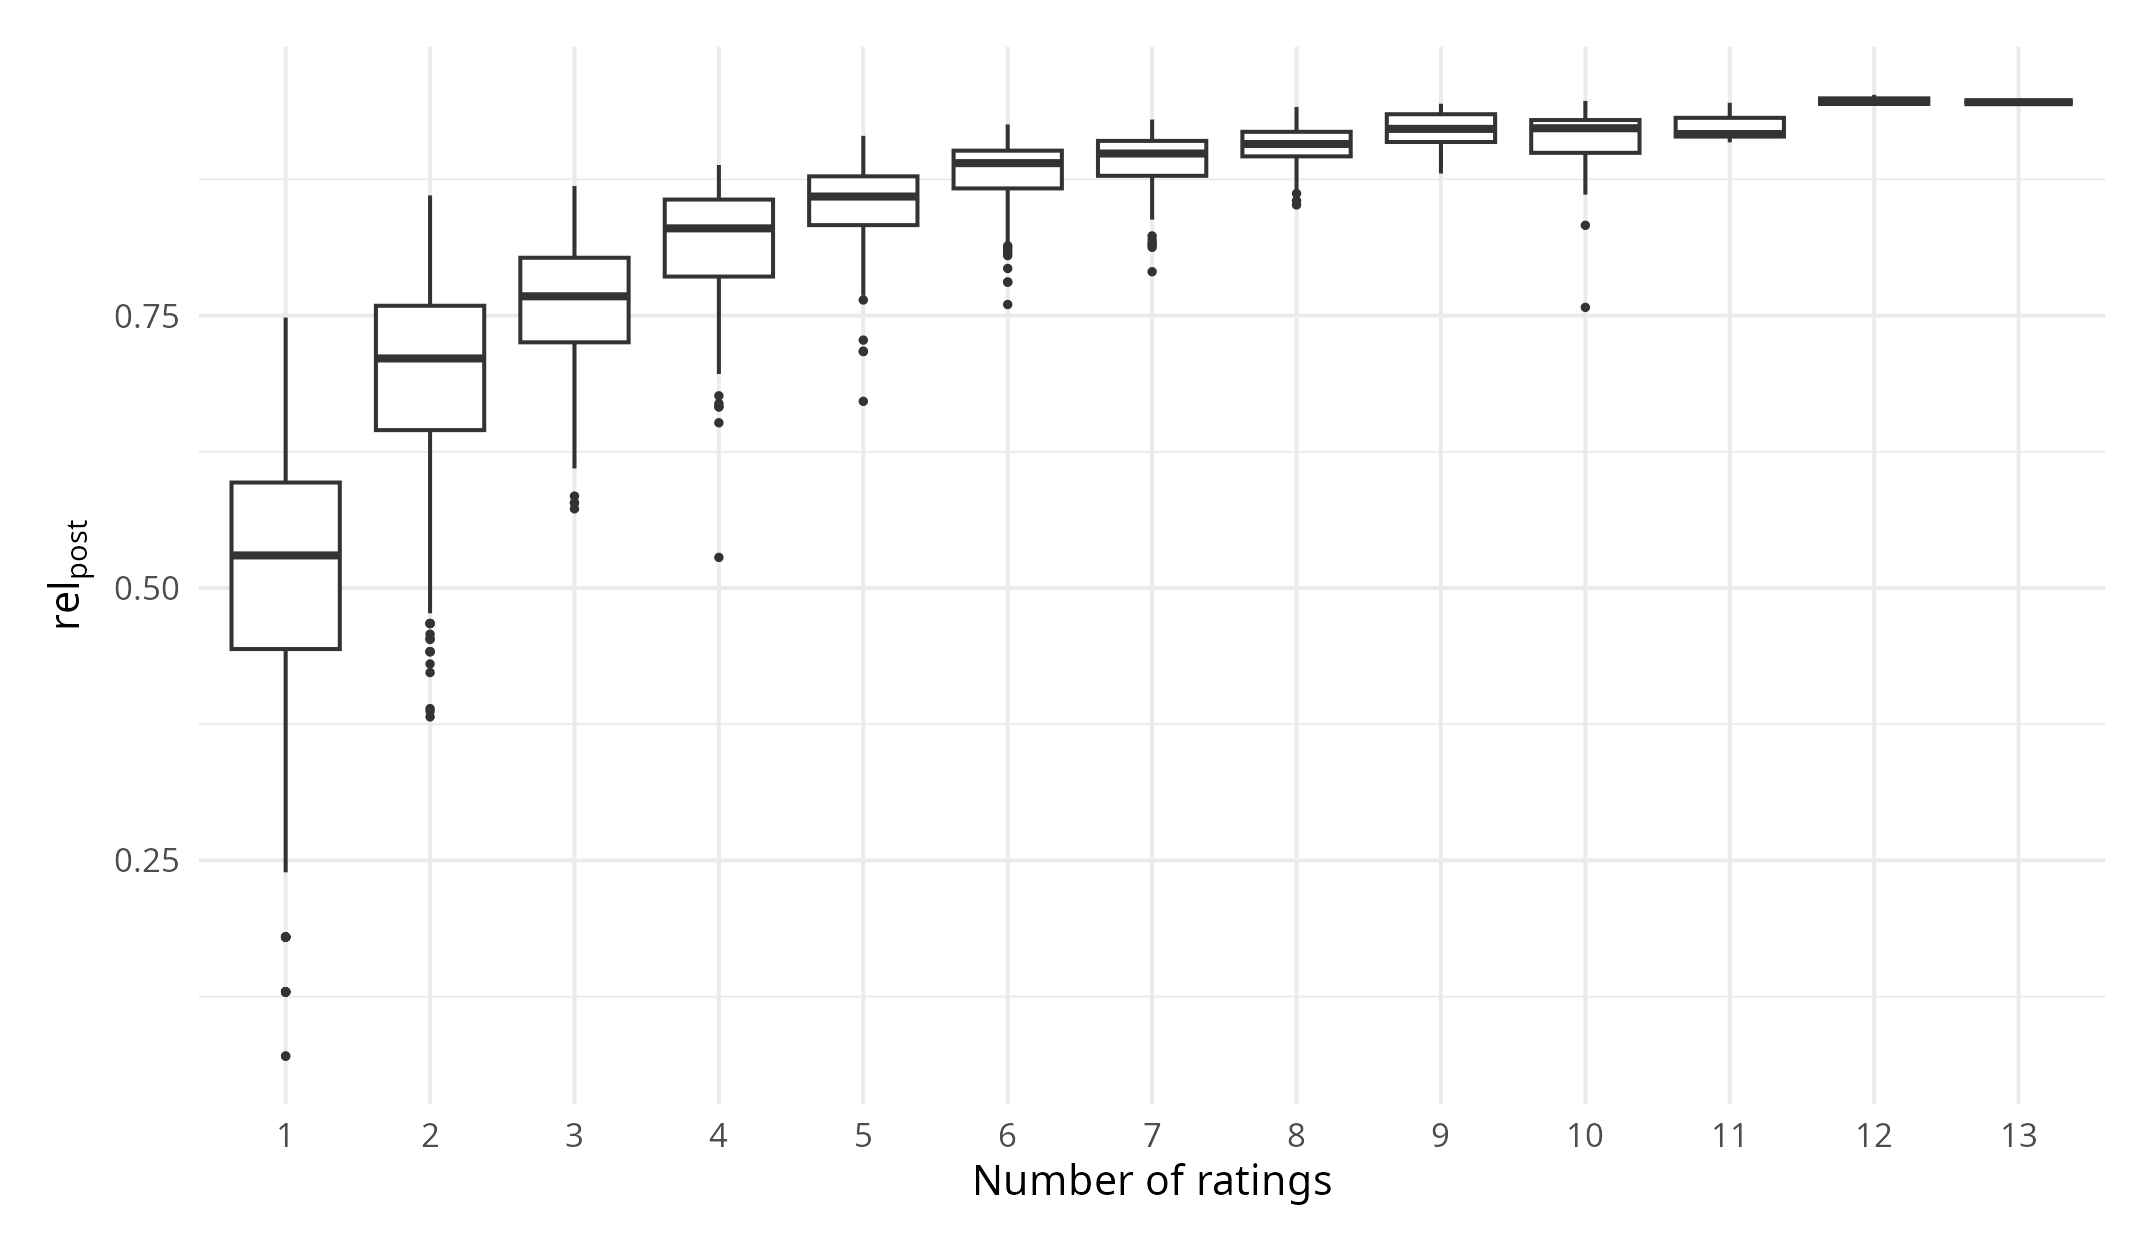

In [13]:
#| label: fig-grm-rel-post-by-n
#| fig-cap: "Product-level reliability (1 − PSD²) by number of ratings per product."
show_png("grm_rel_post_by_n_ratings.png")

**Uncertainty of the marginal reliabilities.** 95% intervals from 200 draws of the model parameters from their asymptotic normal distribution (estimates and Oakes covariance matrix). For the empirical reliability, products are also resampled in each draw. Draws counts the accepted draws. A draw is rejected and replaced when it is not a valid GRM, that is when some discrimination a ≤ 0 or some rater's thresholds are out of order; Draws rejected counts these.

In [14]:
#| label: tbl-grm-reliability-ci
#| tbl-cap: "Empirical and model-based marginal reliability of the GRM with 95% intervals from accepted parameter draws; draws that did not give a valid GRM were rejected and replaced."
show_table("reliability_ci.csv", lambda d: d[["quantity", "estimate", "ci_low", "ci_high", "n_draws", "n_draws_rejected"]])

| Quantity                         | Estimate   | 95% CI lower   | 95% CI upper   | Draws   | Draws rejected   |
|:---------------------------------|:-----------|:---------------|:---------------|:--------|:-----------------|
| empirical marginal reliability   | 0.684      | 0.665          | 0.698          | 200     | 34               |
| model based marginal reliability | 0.968      | 0.964          | 0.972          | 200     | 34               |

**Reliability summary.** Empirical marginal reliability of the actual scores, model-based marginal reliability of the hypothetical full panel, the distribution of rel_post = 1 − PSD² across products, and its agreement with the information-based rel_info.

In [15]:
#| label: tbl-grm-reliability-summary
#| tbl-cap: "Reliability of the GRM scores: empirical marginal reliability of the actual EAP scores (primary), model-based marginal reliability of the hypothetical full panel, distribution of the product-level reliability rel_post = 1 - PSD^2, and its agreement with the information-based rel_info."
show_table("reliability_summary.csv")

| Quantity                                                        | Value   |
|:----------------------------------------------------------------|:--------|
| empirical marginal reliability (primary; actual scores)         | 0.684   |
| model based marginal reliability mirt (hypothetical full panel) | 0.968   |
| model based marginal reliability grid (check)                   | 0.968   |
| var theta eap                                                   | 0.685   |
| mean psd squared                                                | 0.316   |
| rel post min                                                    | 0.070   |
| rel post p10                                                    | 0.504   |
| rel post q1                                                     | 0.592   |
| rel post median                                                 | 0.706   |
| rel post q3                                                     | 0.786   |
| rel post p90                                                    | 0.867   |
| rel post max                                                    | 0.953   |
| rel post mean                                                   | 0.684   |
| rel post iqr                                                    | 0.194   |
| consistency cor rel post rel info                               | 0.946   |
| consistency mean diff rel info minus rel post                   | 0.015   |
| consistency max abs diff                                        | 0.366   |
| products abs diff gt 0.1                                        | 237     |

**Naive indices** are reference values for common practice. They are not used downstream.
- **Cronbach's α** (Cronbach, 1951) measures the consistency of the unweighted rater mean. It assumes τ-equivalent raters and complete data, so here it is computed from pairwise covariances and on the largest fully crossed block.
- **Krippendorff's α** (ordinal; Hayes & Krippendorff, 2007) measures the agreement of single ratings, treating raters as interchangeable. Confidence intervals for both come from a bootstrap over products. For the pairwise Cronbach's α, replications in which some rater pair loses all shared products cannot be computed; the interval uses the remaining replications and is approximate (Failed replications in the table).

In [16]:
#| label: tbl-naive-indices
#| tbl-cap: "Cronbach's alpha (consistency of the unweighted rater mean) and Krippendorff's alpha (ordinal agreement of single ratings), each with a 95% bootstrap CI over products (1,000 replications). For the pairwise Cronbach's alpha, replications in which a rater pair lost all shared products could not be computed (Failed replications); its CI is approximate."
_naive = naive_indices()
_missing("cronbach_alpha.csv / krippendorff_alpha.csv") if _naive is None else md_table(pretty_headers(tidy(_naive)))

| Index                                                     | Value   | 95% CI lower   | 95% CI upper   | Raters   | Products   | Bootstrap replications   | Failed replications   |
|:----------------------------------------------------------|:--------|:---------------|:---------------|:---------|:-----------|:-------------------------|:----------------------|
| Cronbach's alpha: pairwise covariances, all usable raters | 0.949   | 0.928          | 0.959          | 18       | 1,946      | 1,000                    | 375                   |
| Cronbach's alpha: fully crossed block (listwise complete) | 0.750   | 0.686          | 0.799          | 3        | 261        | 1,000                    | 0                     |
| Krippendorff's alpha (ordinal)                            | 0.395   | –              | –              | 24       | 2,905      | 0                        | 0                     |

Distribution of product-level reliability across products.

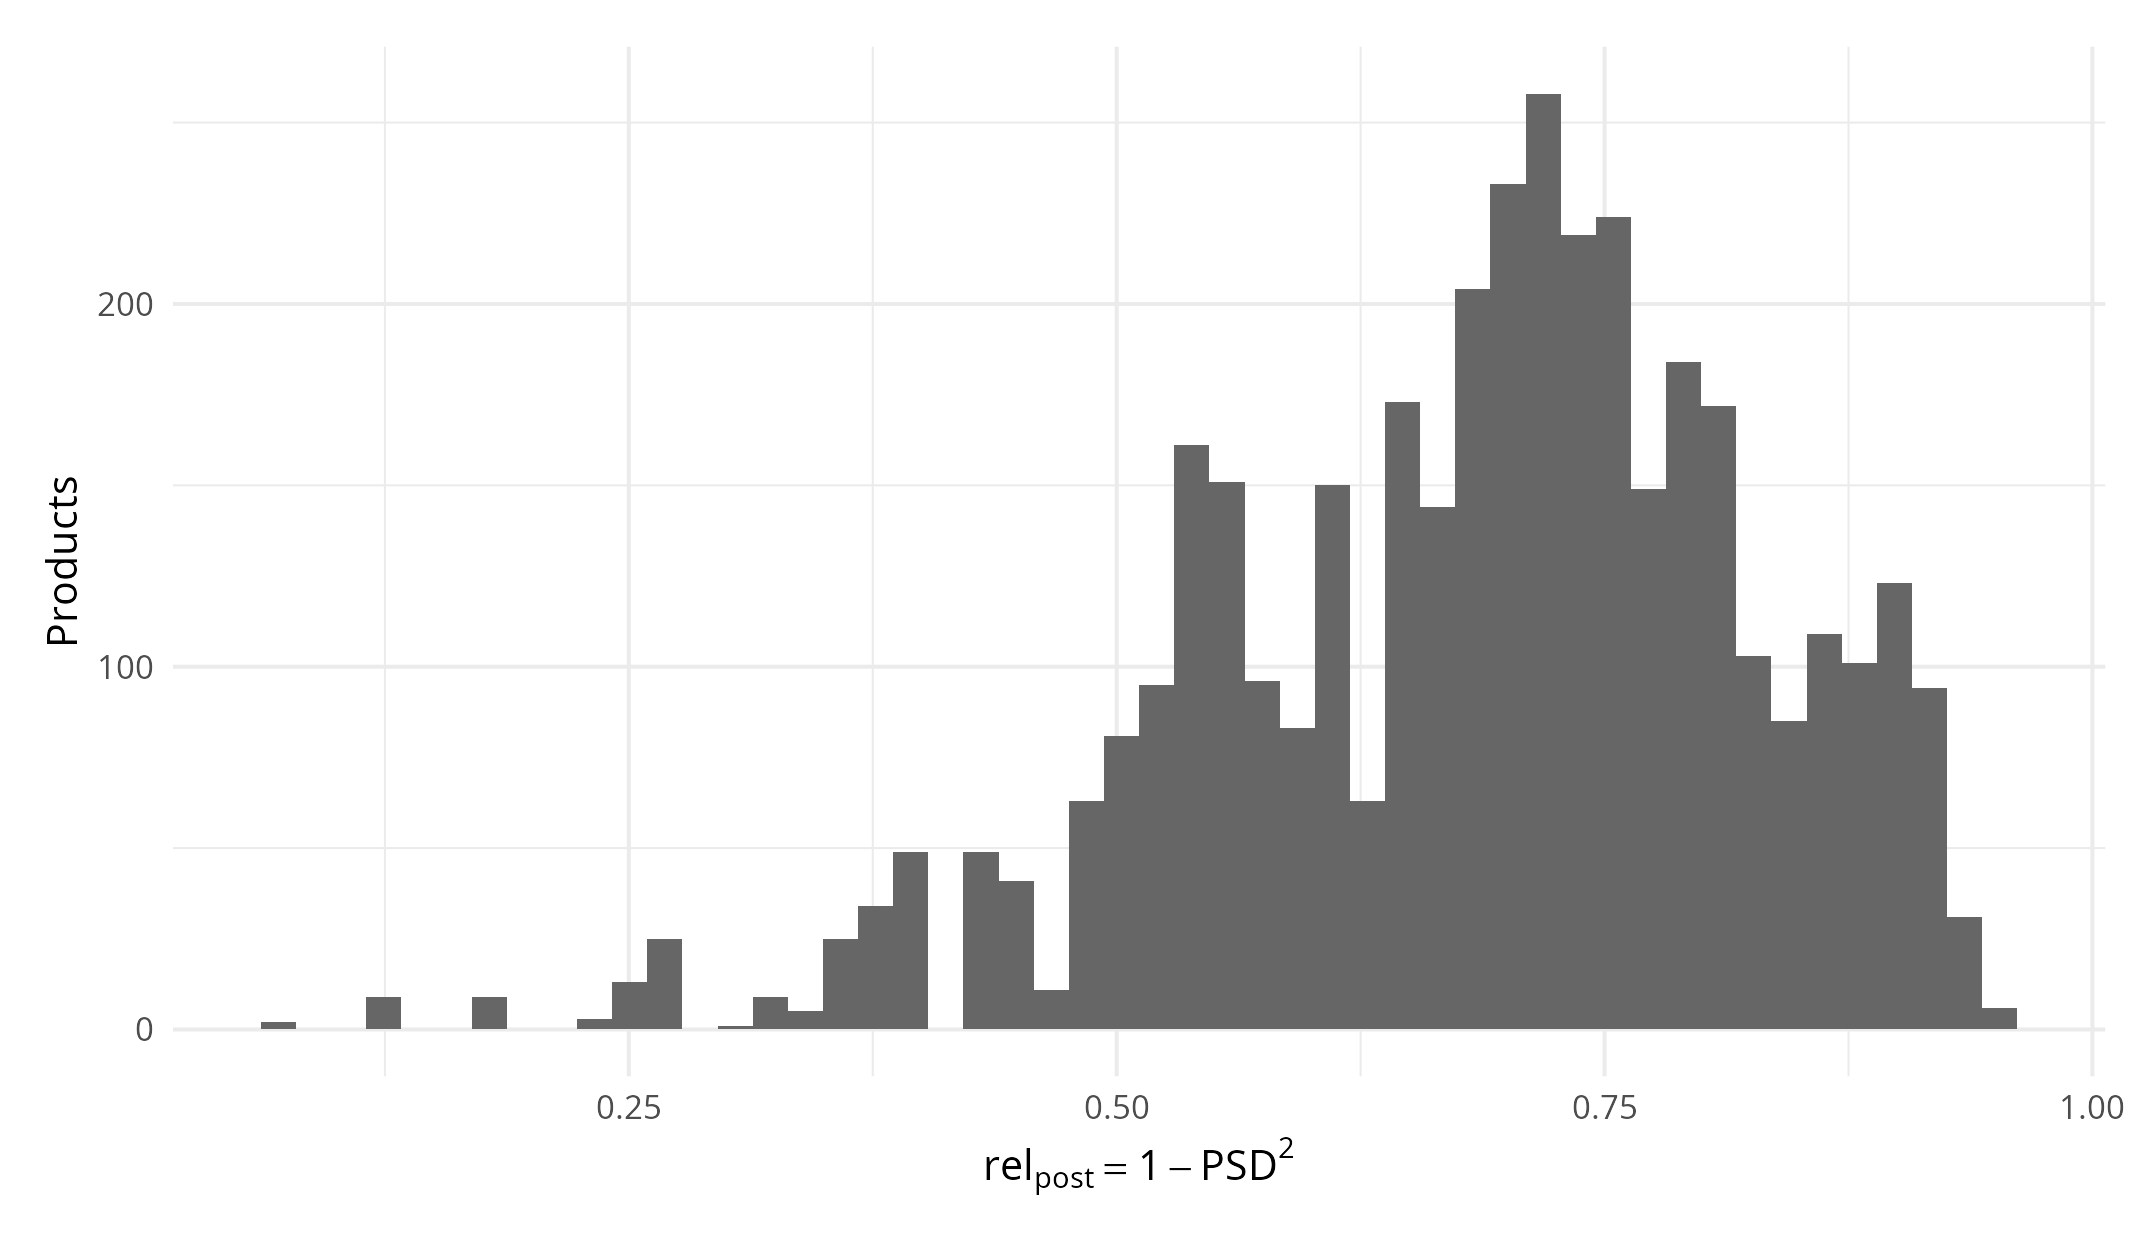

In [17]:
#| label: fig-grm-rel-post-histogram
#| fig-cap: "Distribution of the product-level reliability (1 − PSD²) across all products."
show_png("grm_rel_post_histogram.png")

Product-level reliability by estimated creativity. Precision depends on where a product lies relative to its raters' thresholds.

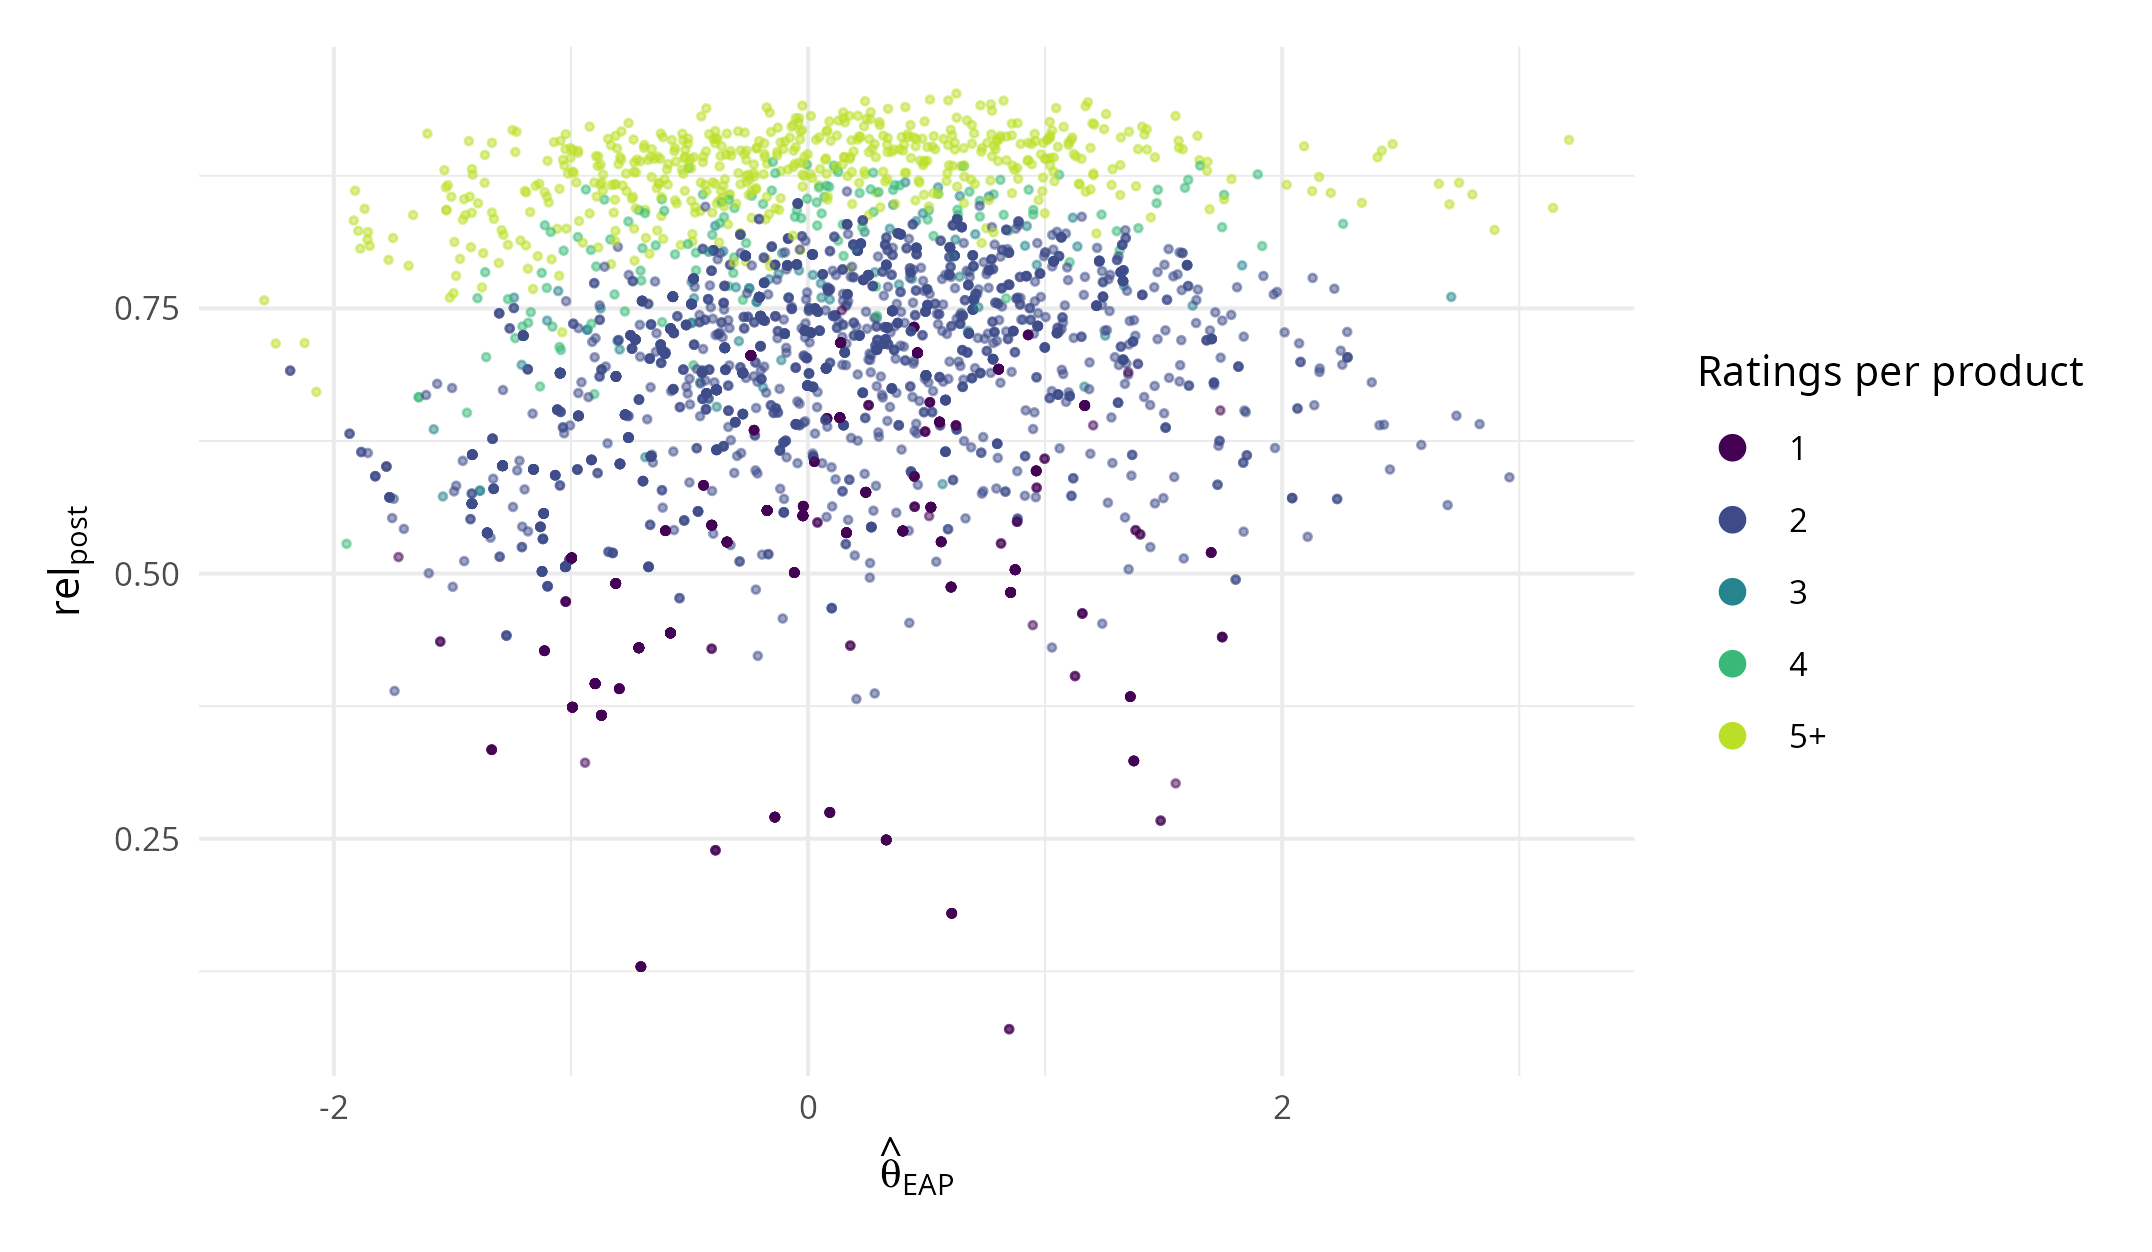

In [18]:
#| label: fig-grm-rel-post-by-theta
#| fig-cap: "Product-level reliability (1 − PSD²) by EAP estimate, coloured by number of ratings per product."
show_png("grm_rel_post_by_theta.png")

**Check.** Two routes to the same product-level reliability: from the posterior (rel_post) and from the information of the product's own raters (rel_info). Points near the diagonal mean the two routes agree.

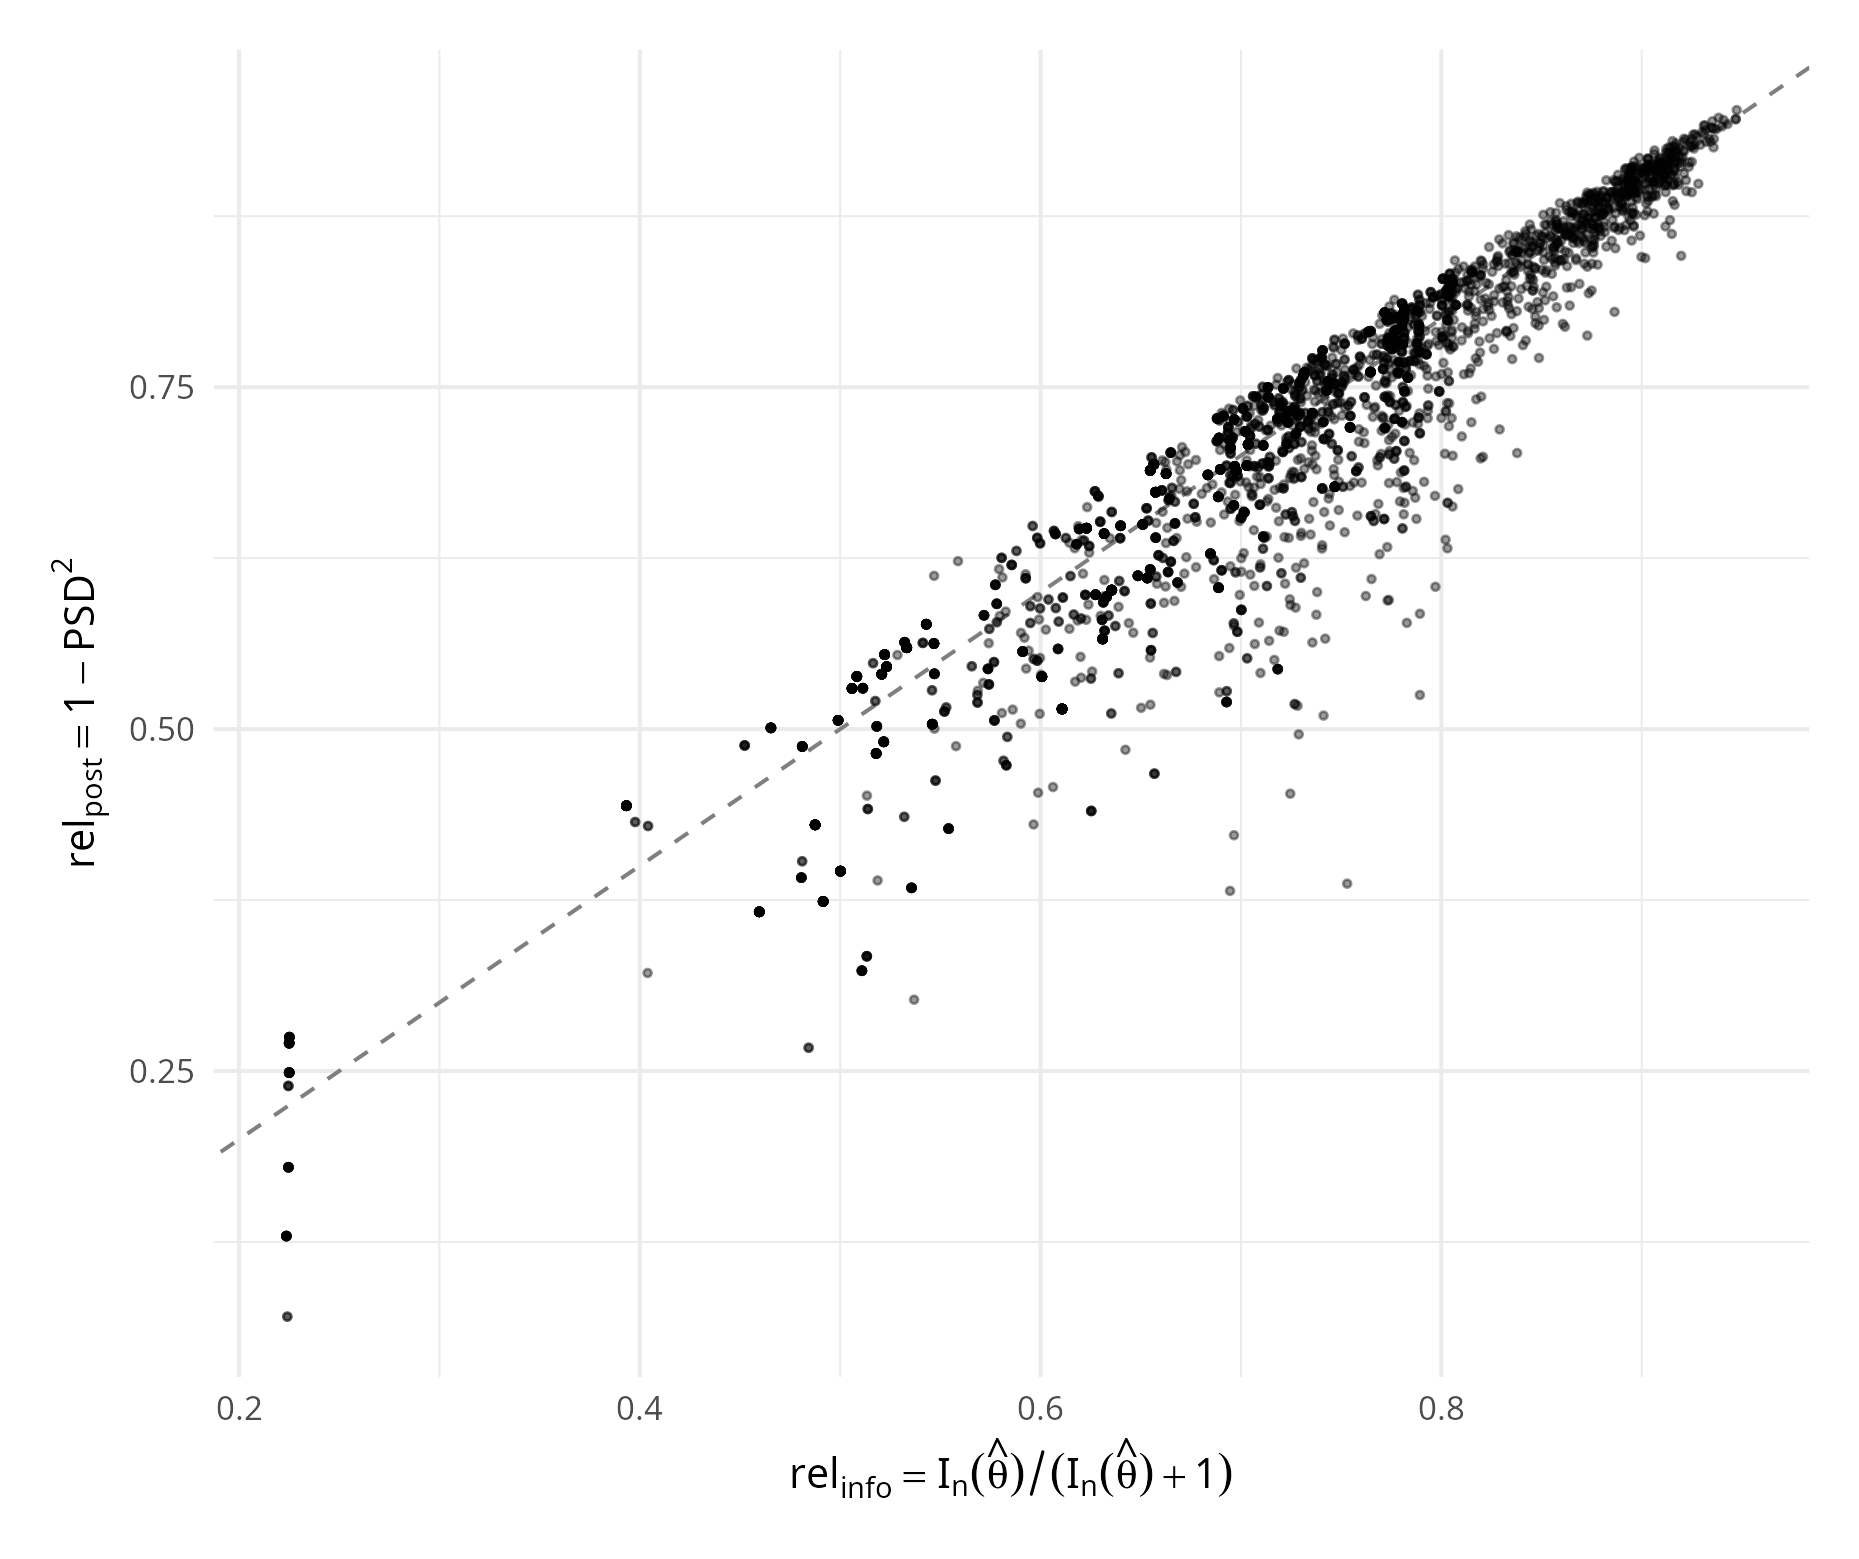

In [19]:
#| label: fig-grm-rel-consistency
#| fig-cap: "Agreement of the two product-level reliability indices: rel_info (information of the product's own raters at the EAP estimate) and rel_post (1 − PSD²)."
show_png("grm_rel_consistency.png", width=6)

**Full panel.** Information and conditional reliability I/(I+1) if every rater rated a product. This is a hypothetical upper bound, not the precision of the actual scores.

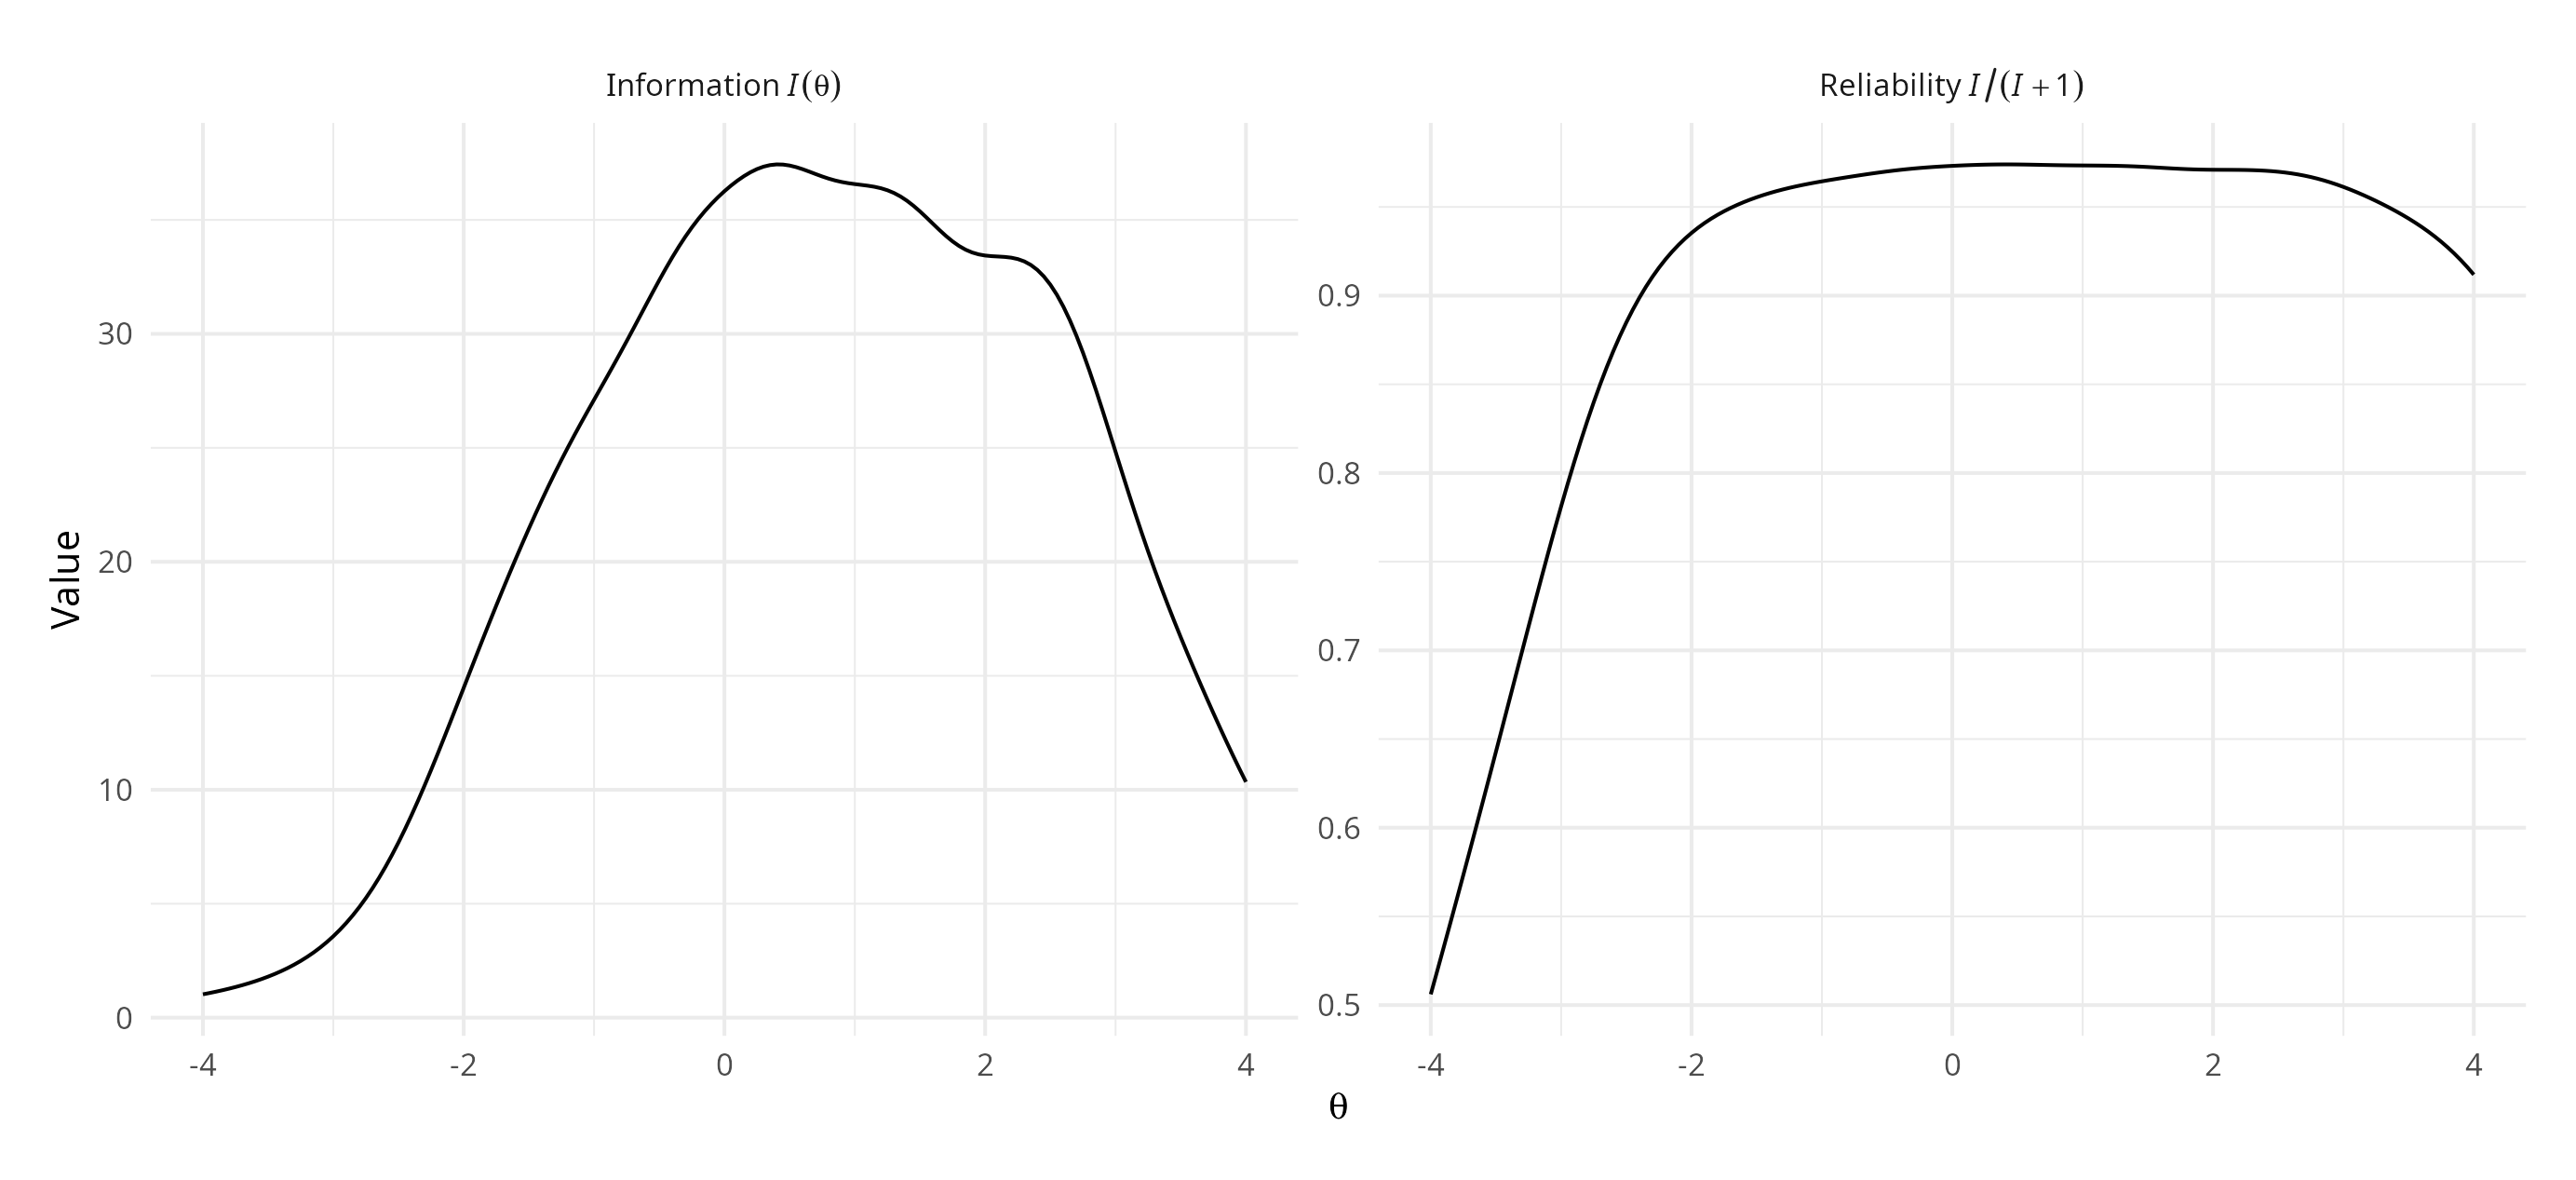

In [20]:
#| label: fig-grm-panel-information
#| fig-cap: "Information and conditional reliability I/(I+1) of the full panel. The curve is hypothetical: it applies to a product rated by all raters."
show_png("grm_panel_information_reliability.png")

## 4. Simulated reliability by number of ratings

**Projected reliability with more ratings.** A model-based gauge of the value of adding ratings, complementing the observed values. Products with θ ~ N(0, 1) are simulated; each gets k ratings from k raters of the actual panel, drawn at random, with ratings generated from the fitted GRM and scored with its parameters (treated as known). The table gives the empirical marginal reliability (mean and 95% range over replications) and the mean product-level reliability rel_post.

In [21]:
#| label: tbl-grm-reliability-projection
#| tbl-cap: "Projected reliability of GRM scores by number of ratings per product (k), simulated from the fitted model with raters of the panel drawn at random (each equally likely): empirical marginal reliability with its 95% range over 50 replications of 2,000 products, and mean product-level reliability (1 − PSD²)."
show_table("reliability_projection.csv", lambda d: pd.DataFrame({"k": d["k"], "empirical": est_ci(d, "empirical", "empirical_q025", "empirical_q975", digits=3), "mean_rel_post": d["mean_rel_post"]}))

| Ratings per product (k)   | Empirical reliability [95% range]   | Mean rel_post   |
|:--------------------------|:------------------------------------|:----------------|
| 1                         | 0.522 [0.504, 0.536]                | 0.522           |
| 2                         | 0.697 [0.688, 0.706]                | 0.698           |
| 3                         | 0.781 [0.772, 0.790]                | 0.781           |
| 4                         | 0.828 [0.821, 0.836]                | 0.829           |
| 5                         | 0.860 [0.853, 0.867]                | 0.859           |
| 6                         | 0.881 [0.875, 0.884]                | 0.881           |
| 7                         | 0.896 [0.893, 0.900]                | 0.897           |
| 8                         | 0.908 [0.904, 0.912]                | 0.909           |
| 9                         | 0.918 [0.914, 0.923]                | 0.918           |
| 10                        | 0.926 [0.923, 0.929]                | 0.926           |

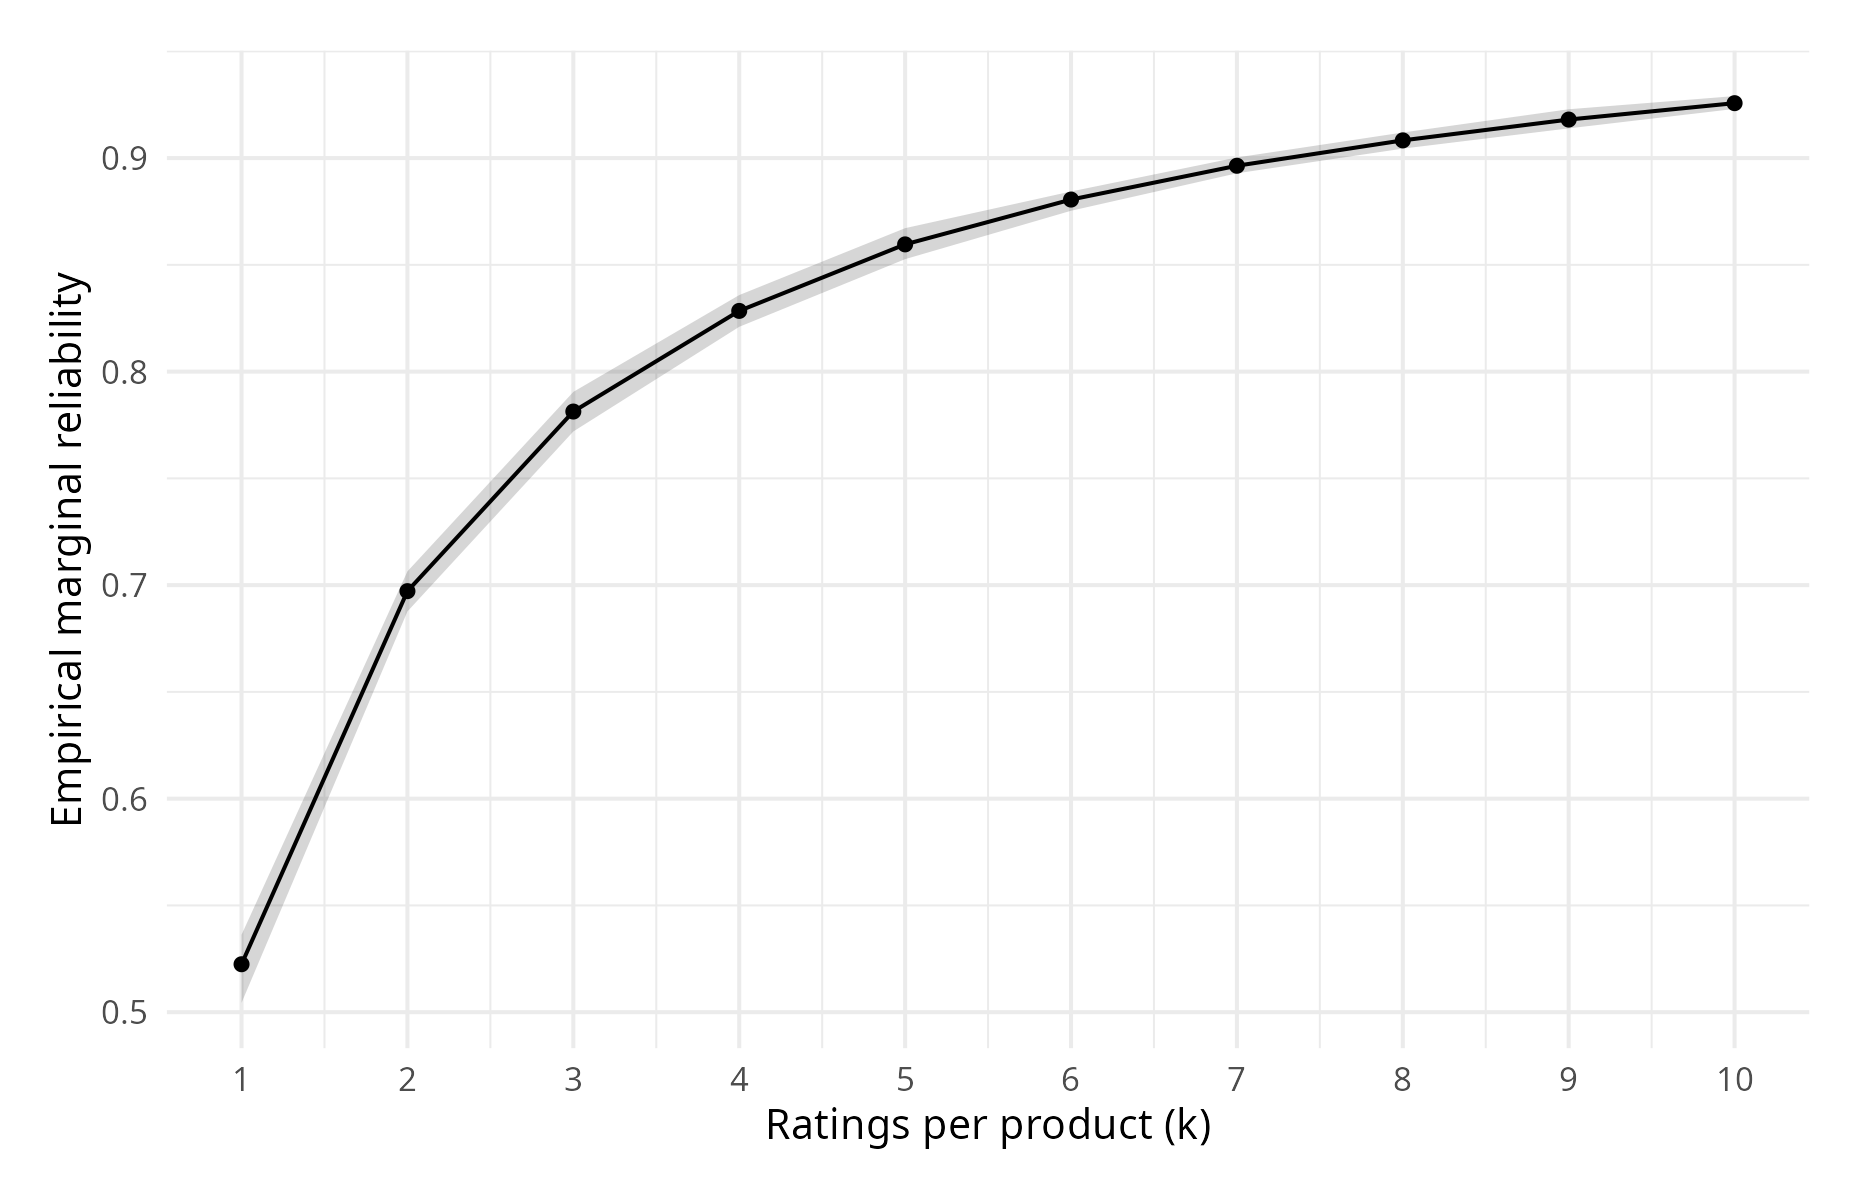

In [22]:
#| label: fig-grm-reliability-projection
#| fig-cap: "Projected empirical marginal reliability by number of ratings per product, simulated from the fitted GRM with randomly drawn raters. Band: 95% range over replications."
show_png("grm_reliability_projection.png", width=6)

Observed and simulated reliability by number of ratings side by side. Observed: mean rel_post of the actual products with that many ratings. Simulated: the projection above (k raters drawn at random per simulated product).

In [23]:
#| label: tbl-grm-reliability-observed-vs-simulated
#| tbl-cap: "Reliability by number of ratings per product: observed mean product-level reliability (1 − PSD²) of the actual products, and simulated empirical marginal reliability with its 95% range over 50 replications (projection with randomly drawn raters)."
_m = read_res("reliability_projection.csv")[["k", "empirical", "empirical_q025", "empirical_q975"]].merge(
    read_res("reliability_by_n_ratings.csv")[["n_ratings", "n_products", "rel_post_mean"]], left_on="k", right_on="n_ratings", how="outer")
_m["k"] = _m["k"].fillna(_m["n_ratings"]).astype(int)
_m = _m.sort_values("k")
md_table(pretty_headers(pd.DataFrame({
    "k": _m["k"],
    "n_products": [("–" if pd.isna(v) else f"{int(v):,}") for v in _m["n_products"]],
    "observed_mean_rel_post": [("–" if pd.isna(v) else f"{v:.3f}") for v in _m["rel_post_mean"]],
    "simulated_empirical": [("–" if pd.isna(e) else f"{e:.3f} [{a:.3f}, {b:.3f}]") for e, a, b in zip(_m["empirical"], _m["empirical_q025"], _m["empirical_q975"])],
})))

| Ratings per product (k)   | Products   | Observed mean rel_post   | Simulated empirical reliability [95% range]   |
|:--------------------------|:-----------|:-------------------------|:----------------------------------------------|
| 1                         | 935        | 0.521                    | 0.522 [0.504, 0.536]                          |
| 2                         | 2,163      | 0.696                    | 0.697 [0.688, 0.706]                          |
| 3                         | 70         | 0.755                    | 0.781 [0.772, 0.790]                          |
| 4                         | 128        | 0.813                    | 0.828 [0.821, 0.836]                          |
| 5                         | 179        | 0.851                    | 0.860 [0.853, 0.867]                          |
| 6                         | 158        | 0.880                    | 0.881 [0.875, 0.884]                          |
| 7                         | 108        | 0.890                    | 0.896 [0.893, 0.900]                          |
| 8                         | 47         | 0.905                    | 0.908 [0.904, 0.912]                          |
| 9                         | 25         | 0.920                    | 0.918 [0.914, 0.923]                          |
| 10                        | 14         | 0.902                    | 0.926 [0.923, 0.929]                          |
| 11                        | 9          | 0.923                    | –                                             |
| 12                        | 3          | 0.947                    | –                                             |
| 13                        | 1          | 0.946                    | –                                             |

## 5. Rater parameters, information and category use

**Rater overview.** One row per rater: number of ratings, raw mean, M1 severity, GRM discrimination, share of the full-panel information with 95% interval, GRM infit and outfit († = infit or outfit outside 0.7–1.3, the flag rule of the rater-fit output), and categories never used. Sorted by M1 severity.

In [24]:
#| label: tbl-rater-overview
#| tbl-cap: "Rater overview sorted by severity: number of ratings, raw mean rating, severity in M1 (rating-scale MFRM), discrimination a in the GRM, share of the full-panel information with 95% interval, GRM infit and outfit mean squares († = infit or outfit outside 0.7–1.3), and categories never used."
_sv = read_res("rater_parameters_by_model.csv")
_sv = _sv[(_sv["model"] == "M1_RSM") & (_sv["parameter"] == "b_rater")][["rater_id", "estimate"]].rename(columns={"estimate": "severity_m1"})
_cc = [f"cat_{i}" for i in range(1, 8)]
_t = (read_res("design_summary_raters.csv")[["rater_id", "n_ratings", "mean"]]
      .merge(_sv, on="rater_id")
      .merge(read_res("rater_parameters.csv")[["rater_id", "a"]], on="rater_id")
      .merge(read_res("rater_information_ci.csv")[["rater_id", "share_weighted", "share_ci_low", "share_ci_high"]], on="rater_id")
      .merge(read_res("rater_fit.csv")[["rater_id", "infit", "outfit", "flag_infit", "flag_outfit"]], on="rater_id")
      .merge(read_res("category_usage.csv")[["rater_id"] + _cc], on="rater_id")
      .sort_values("severity_m1"))
_unused = [",".join(str(j + 1) for j in range(7) if r[_cc[j]] == 0) or "–" for _, r in _t.iterrows()]
md_table(pd.DataFrame({
    "Rater": _t["rater_id"], "Ratings": _t["n_ratings"].astype(int),
    "Mean rating": _t["mean"].map(lambda v: f"{v:.2f}"),
    "Severity (M1)": _t["severity_m1"].map(lambda v: f"{v:.2f}"),
    "a (GRM)": _t["a"].map(lambda v: f"{v:.2f}"),
    "Share of panel information [95% interval]": [f"{100 * s:.1f}% [{100 * l:.1f}, {100 * h:.1f}]" for s, l, h in zip(_t["share_weighted"], _t["share_ci_low"], _t["share_ci_high"])],
    "Infit / outfit (GRM)": [f"{i:.2f} / {o:.2f}" + (" †" if (fi or fo) else "") for i, o, fi, fo in zip(_t["infit"], _t["outfit"], _t["flag_infit"], _t["flag_outfit"])],
    "Unused categories": _unused,
}))

| Rater   | Ratings   | Mean rating   | Severity (M1)   | a (GRM)   | Share of panel information [95% interval]   | Infit / outfit (GRM)   | Unused categories   |
|:--------|:----------|:--------------|:----------------|:----------|:--------------------------------------------|:-----------------------|:--------------------|
| R19     | 250       | 4.01          | -0.98           | 1.87      | 3.3% [1.6, 6.1]                             | 0.55 / 0.57 †          | –                   |
| R18     | 55        | 3.84          | -0.80           | 0.65      | 0.4% [0.0, 1.3]                             | 0.98 / 0.97            | 7                   |
| R24     | 287       | 3.75          | -0.80           | 2.80      | 6.7% [4.4, 9.0]                             | 0.73 / 0.73            | –                   |
| R13     | 254       | 3.68          | -0.68           | 1.51      | 2.0% [1.1, 3.2]                             | 0.85 / 0.85            | –                   |
| R09     | 400       | 3.64          | -0.58           | 0.95      | 0.9% [0.4, 1.7]                             | 0.87 / 0.87            | –                   |
| R23     | 589       | 3.47          | -0.57           | 1.76      | 2.9% [2.1, 3.6]                             | 0.86 / 0.85            | –                   |
| R15     | 73        | 3.47          | -0.46           | 2.78      | 6.3% [2.6, 9.7]                             | 0.76 / 0.68 †          | –                   |
| R12     | 264       | 3.36          | -0.40           | 2.74      | 5.9% [3.0, 9.2]                             | 0.54 / 0.54 †          | –                   |
| R10     | 383       | 3.00          | -0.22           | 2.32      | 4.4% [2.2, 6.3]                             | 0.63 / 0.61 †          | –                   |
| R25     | 138       | 3.03          | -0.19           | 3.04      | 7.4% [4.2, 11.1]                            | 0.73 / 0.72            | 7                   |
| R16     | 328       | 3.07          | -0.19           | 2.42      | 5.0% [3.3, 6.7]                             | 0.81 / 0.79            | –                   |
| R08     | 522       | 3.00          | -0.14           | 2.10      | 3.9% [2.5, 5.7]                             | 0.59 / 0.58 †          | –                   |
| R02     | 873       | 3.03          | -0.06           | 2.74      | 6.2% [3.6, 9.1]                             | 0.43 / 0.40 †          | –                   |
| R03     | 720       | 2.75          | 0.01            | 1.84      | 3.0% [2.0, 4.4]                             | 0.75 / 0.75            | 7                   |
| R26     | 46        | 3.00          | 0.14            | 3.19      | 7.7% [0.5, 18.3]                            | 0.46 / 0.46 †          | 7                   |
| R04     | 620       | 2.82          | 0.17            | 1.95      | 3.3% [2.0, 4.4]                             | 0.63 / 0.59 †          | –                   |
| R05     | 633       | 2.72          | 0.17            | 2.38      | 4.8% [3.0, 6.4]                             | 0.62 / 0.61 †          | –                   |
| R07     | 547       | 2.40          | 0.53            | 1.96      | 3.1% [2.2, 4.3]                             | 0.80 / 0.71            | –                   |
| R11     | 369       | 2.33          | 0.59            | 1.92      | 3.0% [2.0, 4.0]                             | 0.88 / 0.85            | –                   |
| R17     | 52        | 2.08          | 0.69            | 1.86      | 2.6% [0.6, 5.0]                             | 0.92 / 0.92            | 6,7                 |
| R01     | 1174      | 2.16          | 0.76            | 1.80      | 2.6% [1.9, 3.3]                             | 0.72 / 0.69 †          | 7                   |
| R27     | 47        | 2.06          | 0.78            | 2.92      | 5.7% [1.6, 10.8]                            | 0.64 / 0.69 †          | 5,7                 |
| R14     | 327       | 2.22          | 0.84            | 2.36      | 4.0% [2.0, 6.8]                             | 0.55 / 0.47 †          | –                   |
| R06     | 520       | 1.76          | 1.38            | 3.06      | 5.1% [2.7, 7.2]                             | 0.60 / 0.45 †          | 7                   |

**Uncertainty of rater information.** 95% intervals for each rater's average information and share, from the same parameter draws as the reliability intervals. Wide intervals mean that a rater's informativeness is not yet well determined, typically for raters with few ratings.

In [25]:
#| label: tbl-grm-rater-information-ci
#| tbl-cap: "Average information per rating (information integrated over θ ~ N(0, 1)) and share of the full-panel information for each rater, with 95% intervals from 200 accepted parameter draws."
show_table("rater_information_ci.csv", lambda d: pd.DataFrame({"rater_id": d["rater_id"], "n_ratings": d["n_ratings"], "Information per rating [95% interval]": est_ci(d, "info_weighted_area", "info_ci_low", "info_ci_high"), "Share of panel information [95% interval]": est_ci(d, "share_weighted", "share_ci_low", "share_ci_high", digits=3)}))

| Rater   | Ratings by rater   | Information per rating [95% interval]   | Share of panel information [95% interval]   |
|:--------|:-------------------|:----------------------------------------|:--------------------------------------------|
| R01     | 1,174              | 0.85 [0.65, 1.03]                       | 0.026 [0.019, 0.033]                        |
| R02     | 873                | 2.01 [1.20, 2.85]                       | 0.062 [0.036, 0.091]                        |
| R03     | 720                | 0.98 [0.63, 1.34]                       | 0.030 [0.020, 0.044]                        |
| R04     | 620                | 1.06 [0.64, 1.49]                       | 0.033 [0.020, 0.044]                        |
| R05     | 633                | 1.55 [0.96, 2.19]                       | 0.048 [0.030, 0.064]                        |
| R06     | 520                | 1.67 [0.90, 2.37]                       | 0.051 [0.027, 0.072]                        |
| R07     | 547                | 1.02 [0.77, 1.35]                       | 0.031 [0.022, 0.043]                        |
| R08     | 522                | 1.29 [0.78, 1.95]                       | 0.039 [0.025, 0.057]                        |
| R09     | 400                | 0.29 [0.13, 0.50]                       | 0.009 [0.004, 0.017]                        |
| R10     | 383                | 1.43 [0.73, 2.23]                       | 0.044 [0.022, 0.063]                        |
| R11     | 369                | 0.96 [0.64, 1.29]                       | 0.030 [0.020, 0.040]                        |
| R12     | 264                | 1.91 [0.94, 3.00]                       | 0.059 [0.030, 0.092]                        |
| R13     | 254                | 0.66 [0.40, 1.01]                       | 0.020 [0.011, 0.032]                        |
| R14     | 327                | 1.31 [0.70, 2.19]                       | 0.040 [0.020, 0.068]                        |
| R15     | 73                 | 2.04 [0.86, 3.32]                       | 0.063 [0.026, 0.097]                        |
| R16     | 328                | 1.61 [1.08, 2.13]                       | 0.050 [0.033, 0.067]                        |
| R17     | 52                 | 0.85 [0.19, 1.66]                       | 0.026 [0.006, 0.050]                        |
| R18     | 55                 | 0.13 [0.02, 0.42]                       | 0.004 [0.000, 0.013]                        |
| R19     | 250                | 1.07 [0.51, 2.01]                       | 0.033 [0.016, 0.061]                        |
| R23     | 589                | 0.94 [0.72, 1.16]                       | 0.029 [0.021, 0.036]                        |
| R24     | 287                | 2.19 [1.44, 3.05]                       | 0.067 [0.044, 0.090]                        |
| R25     | 138                | 2.40 [1.41, 3.68]                       | 0.074 [0.042, 0.111]                        |
| R26     | 46                 | 2.52 [0.15, 6.61]                       | 0.077 [0.005, 0.183]                        |
| R27     | 47                 | 1.87 [0.48, 3.62]                       | 0.057 [0.016, 0.108]                        |

**Information shares.** Each rater's share of the total information of all raters, along θ.

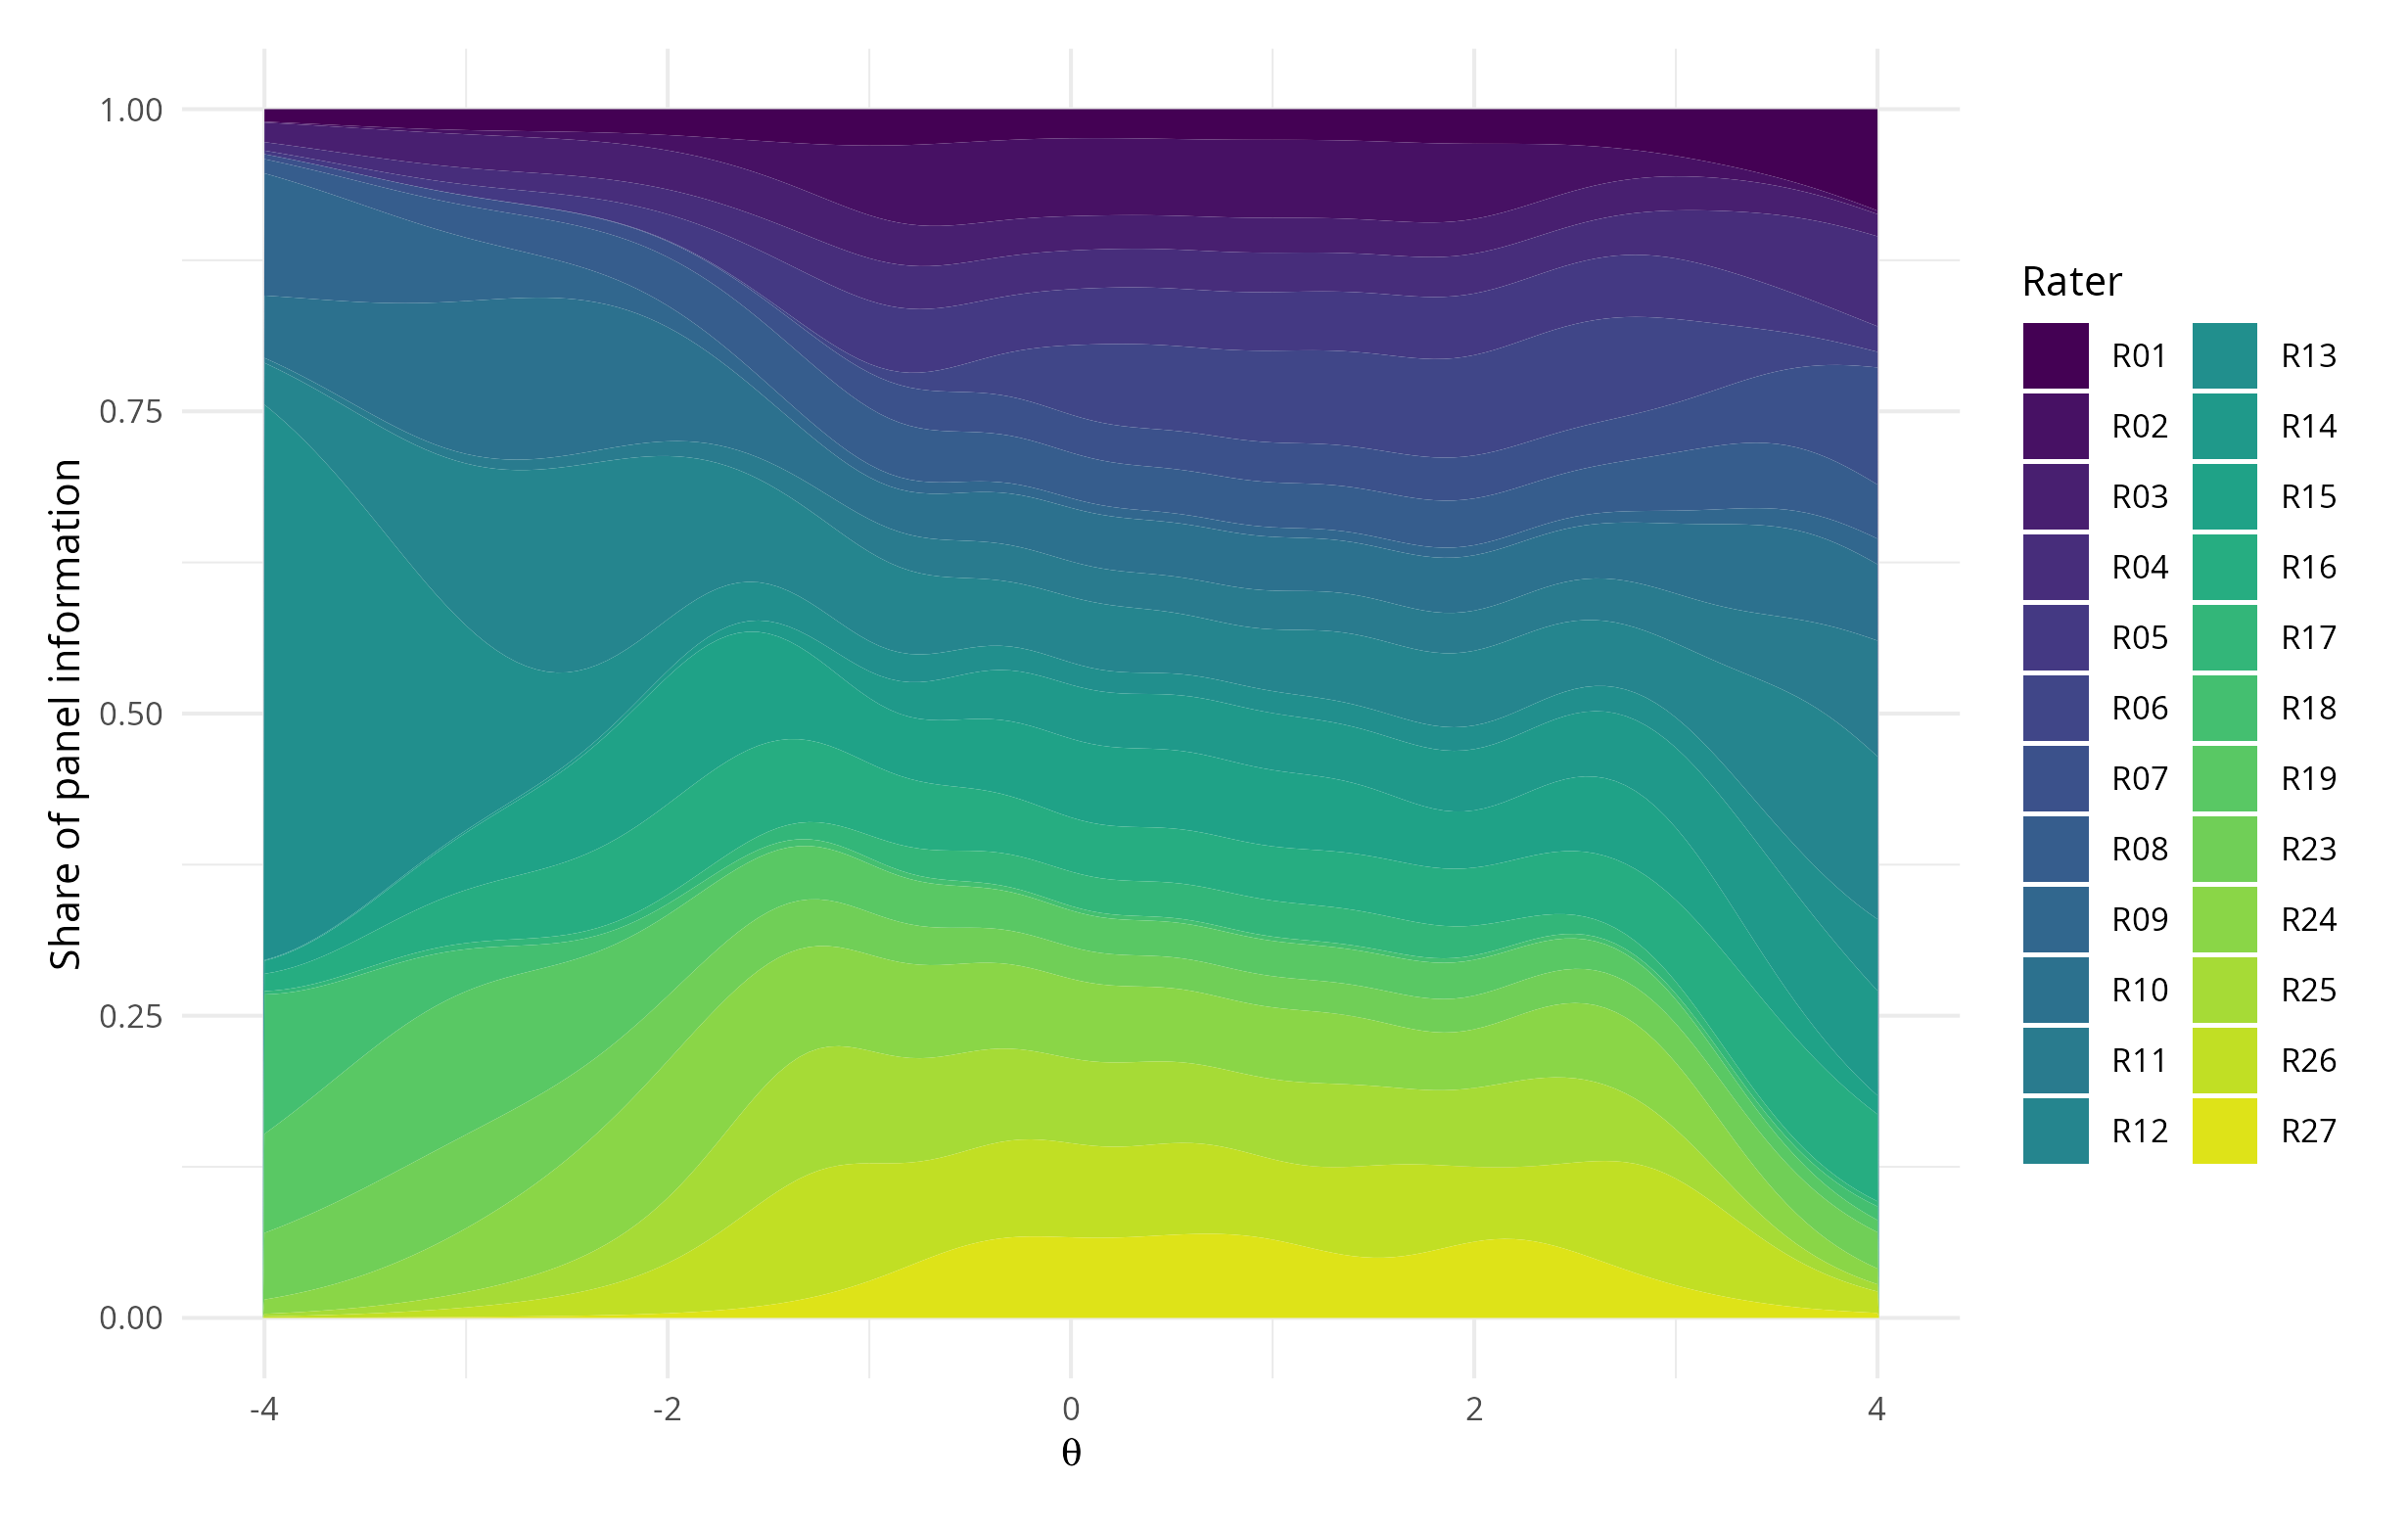

In [26]:
#| label: fig-grm-information-shares
#| fig-cap: "Share of each rater in the information of the full panel across the latent continuum."
show_png("grm_rater_information_shares.png")

**Information summary.** For each rater: information averaged over the N(0, 1) distribution of θ, where it peaks, and the rater's share of the full-panel information.

In [27]:
#| label: tbl-grm-information-summary
#| tbl-cap: "Rater information summary: information integrated over N(0, 1), location and height of the maximum, and share of the full-panel information (weighted over N(0, 1) and at selected values of θ)."
show_table("rater_information_summary.csv")

| Rater   | Ratings by rater   | Information per rating   | θ at maximum   | Maximum information   | Share of panel information   | Share at θ = −2   | Share at θ = −1   | Share at θ = 0   | Share at θ = 1   | Share at θ = 2   |
|:--------|:-------------------|:-------------------------|:---------------|:----------------------|:-----------------------------|:------------------|:------------------|:-----------------|:-----------------|:-----------------|
| R01     | 1,174              | 0.846                    | 2.800          | 0.964                 | 0.026                        | 0.021             | 0.030             | 0.024            | 0.025            | 0.029            |
| R02     | 873                | 2.007                    | 0.400          | 2.375                 | 0.062                        | 0.013             | 0.058             | 0.064            | 0.065            | 0.062            |
| R03     | 720                | 0.978                    | 0.900          | 1.055                 | 0.030                        | 0.032             | 0.036             | 0.028            | 0.029            | 0.029            |
| R04     | 620                | 1.062                    | 0.650          | 1.209                 | 0.033                        | 0.021             | 0.035             | 0.032            | 0.033            | 0.033            |
| R05     | 633                | 1.552                    | 0.650          | 1.776                 | 0.048                        | 0.022             | 0.052             | 0.046            | 0.048            | 0.051            |
| R06     | 520                | 1.665                    | 2.300          | 2.843                 | 0.051                        | 0.001             | 0.007             | 0.057            | 0.076            | 0.083            |
| R07     | 547                | 1.021                    | 1.300          | 1.211                 | 0.031                        | 0.013             | 0.029             | 0.031            | 0.033            | 0.036            |
| R08     | 522                | 1.286                    | 0.300          | 1.371                 | 0.039                        | 0.040             | 0.047             | 0.038            | 0.037            | 0.039            |
| R09     | 400                | 0.286                    | 0.100          | 0.291                 | 0.009                        | 0.018             | 0.011             | 0.008            | 0.008            | 0.008            |
| R10     | 383                | 1.428                    | 0.500          | 1.662                 | 0.044                        | 0.094             | 0.035             | 0.044            | 0.045            | 0.046            |
| R11     | 369                | 0.964                    | 1.200          | 1.175                 | 0.030                        | 0.012             | 0.027             | 0.029            | 0.032            | 0.033            |
| R12     | 264                | 1.913                    | 1.450          | 2.087                 | 0.059                        | 0.135             | 0.074             | 0.054            | 0.051            | 0.062            |
| R13     | 254                | 0.665                    | -0.600         | 0.680                 | 0.020                        | 0.043             | 0.025             | 0.018            | 0.018            | 0.020            |
| R14     | 327                | 1.309                    | 0.800          | 1.730                 | 0.040                        | 0.005             | 0.022             | 0.045            | 0.047            | 0.051            |
| R15     | 73                 | 2.044                    | 0.400          | 2.434                 | 0.063                        | 0.105             | 0.054             | 0.065            | 0.063            | 0.047            |
| R16     | 328                | 1.615                    | 2.600          | 1.703                 | 0.050                        | 0.075             | 0.060             | 0.045            | 0.045            | 0.048            |
| R17     | 52                 | 0.850                    | 0.800          | 1.092                 | 0.026                        | 0.008             | 0.019             | 0.028            | 0.030            | 0.025            |
| R18     | 55                 | 0.131                    | -0.450         | 0.133                 | 0.004                        | 0.009             | 0.005             | 0.004            | 0.004            | 0.004            |
| R19     | 250                | 1.065                    | -0.450         | 1.097                 | 0.033                        | 0.067             | 0.040             | 0.030            | 0.029            | 0.030            |
| R23     | 589                | 0.938                    | 0.300          | 0.961                 | 0.029                        | 0.054             | 0.035             | 0.026            | 0.026            | 0.028            |
| R24     | 287                | 2.193                    | -0.200         | 2.395                 | 0.067                        | 0.113             | 0.080             | 0.066            | 0.059            | 0.049            |
| R25     | 138                | 2.398                    | -0.450         | 2.624                 | 0.074                        | 0.054             | 0.093             | 0.070            | 0.066            | 0.065            |
| R26     | 46                 | 2.520                    | -0.100         | 2.838                 | 0.077                        | 0.041             | 0.097             | 0.078            | 0.066            | 0.062            |
| R27     | 47                 | 1.873                    | 0.600          | 2.583                 | 0.057                        | 0.004             | 0.031             | 0.067            | 0.065            | 0.063            |

## 6. Adjacent-category ladder

**Likelihood-ratio tests.** Each test checks whether the next step up the ladder improves fit: rater-specific thresholds (M1 vs M2), then rater-specific discriminations (M2 vs M3). "df if all categories used" is the df if every rater used all 7 categories: (J − 1)(K − 2) for M1 vs M2 and J − 1 for M2 vs M3, with J raters and K categories. A rater who never uses an end category of the scale has one step parameter less in M2 (see the category-use table), so the observed df of M1 vs M2 is smaller by the number of categories raters never used (unused end categories and any internal gap).

In [28]:
#| label: tbl-lr-tests
#| tbl-cap: "Likelihood-ratio tests within the adjacent-category ladder. 'df if all categories used' gives the df if every rater had used all 7 categories; unused end categories reduce the df of M1 vs M2."
show_table("lr_tests.csv", lambda d: d[["comparison", "X2", "df", "df_expected_formula", "df_matches_formula", "p"]])

| Comparison                               | χ²      | df   | df if all categories used   | df equal   | p      |
|:-----------------------------------------|:--------|:-----|:----------------------------|:-----------|:-------|
| M1 vs M2: rater-specific thresholds      | 855.358 | 105  | 115                         | False      | < .001 |
| M2 vs M3: rater-specific discriminations | 160.076 | 23   | 23                          | True       | < .001 |

Rater discriminations in M3. Their spread shows how far the equal-discrimination assumption of M1 and M2 is from the data.

In [29]:
#| label: tbl-discrimination-m3
#| tbl-cap: "Rater discriminations in the generalized partial credit model (M3)."
show_table("discrimination_m3.csv", lambda d: d[["rater_id", "n_ratings", "estimate", "se"]])

| Rater   | Ratings by rater   | Estimate   | SE    |
|:--------|:-------------------|:-----------|:------|
| R18     | 55                 | 0.301      | 0.140 |
| R09     | 400                | 0.310      | 0.056 |
| R17     | 52                 | 0.836      | 0.286 |
| R23     | 589                | 0.846      | 0.081 |
| R13     | 254                | 0.876      | 0.152 |
| R03     | 720                | 0.876      | 0.112 |
| R19     | 250                | 0.896      | 0.248 |
| R04     | 620                | 0.940      | 0.148 |
| R11     | 369                | 0.958      | 0.131 |
| R07     | 547                | 1.055      | 0.119 |
| R08     | 522                | 1.095      | 0.173 |
| R14     | 327                | 1.149      | 0.286 |
| R05     | 633                | 1.210      | 0.158 |
| R01     | 1,174              | 1.216      | 0.108 |
| R02     | 873                | 1.385      | 0.284 |
| R10     | 383                | 1.390      | 0.277 |
| R16     | 328                | 1.549      | 0.196 |
| R15     | 73                 | 1.675      | 0.441 |
| R24     | 287                | 1.695      | 0.240 |
| R26     | 46                 | 2.026      | 1.181 |
| R25     | 138                | 2.028      | 0.411 |
| R06     | 520                | 2.084      | 0.379 |
| R27     | 47                 | 2.104      | 0.804 |
| R12     | 264                | 2.218      | 0.526 |

In [30]:
#| label: tbl-discrimination-summary
#| tbl-cap: "Spread of the rater discriminations in M3 (GPCM): minimum, quartiles, median, maximum, ratio of the largest to the smallest discrimination, and standard deviation across raters."
show_table("discrimination_summary.csv")

| Statistic     | Value   |
|:--------------|:--------|
| min           | 0.301   |
| q1            | 0.891   |
| median        | 1.180   |
| q3            | 1.680   |
| max           | 2.218   |
| ratio max min | 7.360   |
| sd            | 0.545   |

Raters whose adjacent-category step parameters are out of order. In adjacent-category models this means that some category is never the most likely response (Andrich, 1978). In the GRM, thresholds are ordered by construction.

In [31]:
#| label: tbl-threshold-order
#| tbl-cap: "Raters with unordered step parameters in M2 (partial-credit MFRM) and M3 (GPCM)."
show_table("threshold_order.csv", lambda d: d[~d["ordered"]])

| Model                    | Rater   | Steps   | Ordered   | Reversals   | Step parameters                  |
|:-------------------------|:--------|:--------|:----------|:------------|:---------------------------------|
| M2 (partial-credit MFRM) | R03     | 5       | False     | 1           | -0.90;-0.24;1.09;0.68;2.65       |
| M2 (partial-credit MFRM) | R04     | 6       | False     | 1           | -0.56;0.59;0.70;0.56;2.25;3.88   |
| M2 (partial-credit MFRM) | R05     | 6       | False     | 1           | -0.78;0.58;0.56;1.45;1.80;2.71   |
| M2 (partial-credit MFRM) | R06     | 5       | False     | 1           | 0.88;1.24;1.59;2.86;2.38         |
| M2 (partial-credit MFRM) | R11     | 6       | False     | 1           | -0.33;1.02;1.14;1.03;2.78;4.31   |
| M2 (partial-credit MFRM) | R15     | 6       | False     | 1           | -2.24;0.36;0.38;0.19;1.36;3.25   |
| M2 (partial-credit MFRM) | R17     | 4       | False     | 2           | 0.47;0.17;1.31;1.06              |
| M2 (partial-credit MFRM) | R27     | 4       | False     | 1           | 0.21;0.87;0.48;3.04              |
| M3 (GPCM)                | R03     | 5       | False     | 1           | -0.81;-0.21;1.17;0.59;2.70       |
| M3 (GPCM)                | R04     | 6       | False     | 1           | -0.52;0.61;0.67;0.46;2.18;3.81   |
| M3 (GPCM)                | R06     | 5       | False     | 1           | 0.43;0.99;1.39;2.21;2.20         |
| M3 (GPCM)                | R09     | 6       | False     | 2           | -0.42;-0.72;0.60;-0.06;1.09;3.70 |
| M3 (GPCM)                | R11     | 6       | False     | 1           | -0.25;1.08;1.15;0.98;2.75;4.23   |
| M3 (GPCM)                | R15     | 6       | False     | 1           | -1.81;0.16;0.35;0.34;1.18;2.70   |
| M3 (GPCM)                | R17     | 4       | False     | 2           | 0.73;0.20;1.43;0.92              |
| M3 (GPCM)                | R18     | 5       | False     | 1           | -7.46;-2.16;0.46;-0.72;5.16      |

Infit and outfit under M1, the fit statistics usually reported for many-facet Rasch models (Eckes, 2015).

In [32]:
#| label: tbl-rater-fit-m1
#| tbl-cap: "Rater infit and outfit mean squares under M1 (rating-scale MFRM)."
show_table("rater_fit_m1.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit"]])

| Rater   | Ratings by rater   | Infit   | Outfit   |
|:--------|:-------------------|:--------|:---------|
| R01     | 1,174              | 0.497   | 0.511    |
| R02     | 873                | 0.836   | 0.827    |
| R03     | 720                | 0.668   | 0.667    |
| R04     | 620                | 0.732   | 0.699    |
| R05     | 633                | 0.747   | 0.720    |
| R06     | 520                | 0.898   | 0.704    |
| R07     | 547                | 0.906   | 0.811    |
| R08     | 522                | 0.576   | 0.584    |
| R09     | 400                | 1.113   | 1.089    |
| R10     | 383                | 0.445   | 0.425    |
| R11     | 369                | 1.002   | 0.954    |
| R12     | 264                | 0.262   | 0.280    |
| R13     | 254                | 0.457   | 0.462    |
| R14     | 327                | 0.767   | 0.716    |
| R15     | 73                 | 0.790   | 0.740    |
| R16     | 328                | 0.524   | 0.546    |
| R17     | 52                 | 1.332   | 1.146    |
| R18     | 55                 | 1.190   | 1.252    |
| R19     | 250                | 0.497   | 0.535    |
| R23     | 589                | 0.778   | 0.771    |
| R24     | 287                | 0.620   | 0.619    |
| R25     | 138                | 0.456   | 0.487    |
| R26     | 46                 | 0.333   | 0.363    |
| R27     | 47                 | 0.728   | 0.738    |

**Agreement of scores.** Correlations of the product scores between models. High values mean the ranking of products hardly depends on the model.

In [33]:
#| label: tbl-theta-correlations
#| tbl-cap: "Correlations of the EAP estimates between models (Pearson and Spearman). 'M1, sirt default grid' is M1 re-estimated with the default quadrature grid of sirt, as a software check."
show_table("theta_correlations.csv")

| Method   | Model                    | M1 (rating-scale MFRM)   | M2 (partial-credit MFRM)   | M3 (GPCM)   | GRM   | M1, sirt default grid   |
|:---------|:-------------------------|:-------------------------|:---------------------------|:------------|:------|:------------------------|
| Pearson  | M1 (rating-scale MFRM)   | 1.000                    | 0.993                      | 0.982       | 0.978 | 1.000                   |
| Pearson  | M2 (partial-credit MFRM) | 0.993                    | 1.000                      | 0.990       | 0.986 | 0.993                   |
| Pearson  | M3 (GPCM)                | 0.982                    | 0.990                      | 1.000       | 0.996 | 0.982                   |
| Pearson  | GRM                      | 0.978                    | 0.986                      | 0.996       | 1.000 | 0.978                   |
| Pearson  | M1, sirt default grid    | 1.000                    | 0.993                      | 0.982       | 0.978 | 1.000                   |
| Spearman | M1 (rating-scale MFRM)   | 1.000                    | 0.996                      | 0.985       | 0.980 | 1.000                   |
| Spearman | M2 (partial-credit MFRM) | 0.996                    | 1.000                      | 0.988       | 0.984 | 0.996                   |
| Spearman | M3 (GPCM)                | 0.985                    | 0.988                      | 1.000       | 0.996 | 0.985                   |
| Spearman | GRM                      | 0.980                    | 0.984                      | 0.996       | 1.000 | 0.980                   |
| Spearman | M1, sirt default grid    | 1.000                    | 0.996                      | 0.985       | 0.980 | 1.000                   |

Marginal reliability (hypothetical full panel) and empirical reliability (actual scores) for each model.

In [34]:
#| label: tbl-marginal-reliability-models
#| tbl-cap: "Marginal and empirical reliability by model, for comparison."
show_table("marginal_reliability.csv")

| Model                    | Latent variance   | Marginal reliability   | marginal_rxx (mirt)   | Empirical reliability   |
|:-------------------------|:------------------|:-----------------------|:----------------------|:------------------------|
| M1 (rating-scale MFRM)   | 1.069             | 0.958                  | –                     | 0.653                   |
| M2 (partial-credit MFRM) | 1.150             | 0.957                  | –                     | 0.659                   |
| M3 (GPCM)                | 1.000             | 0.964                  | 0.964                 | 0.671                   |
| GRM                      | 1.000             | 0.968                  | 0.968                 | 0.684                   |

## References

- Andrich, D. (1978). A rating formulation for ordered response categories. *Psychometrika, 43*(4), 561–573.
- Cai, L., & Monroe, S. (2014). *A new statistic for evaluating item response theory models for ordinal data* (CRESST Report 839). University of California, Los Angeles.
- Chalmers, R. P. (2012). mirt: A multidimensional item response theory package for the R environment. *Journal of Statistical Software, 48*(6), 1–29.
- Christensen, K. B., Makransky, G., & Horton, M. (2017). Critical values for Yen's Q3: Identification of local dependence in the Rasch model using residual correlations. *Applied Psychological Measurement, 41*(3), 178–194.
- Cronbach, L. J. (1951). Coefficient alpha and the internal structure of tests. *Psychometrika, 16*(3), 297–334.
- Eckes, T. (2015). *Introduction to many-facet Rasch measurement* (2nd ed.). Peter Lang.
- Green, B. F., Bock, R. D., Humphreys, L. G., Linn, R. L., & Reckase, M. D. (1984). Technical guidelines for assessing computerized adaptive tests. *Journal of Educational Measurement, 21*(4), 347–360.
- Hayes, A. F., & Krippendorff, K. (2007). Answering the call for a standard reliability measure for coding data. *Communication Methods and Measures, 1*(1), 77–89.
- Kang, T., & Chen, T. T. (2008). Performance of the generalized S-X² item fit index for polytomous IRT models. *Journal of Educational Measurement, 45*(4), 391–406.
- Linacre, J. M. (1989). *Many-facet Rasch measurement*. MESA Press.
- Masters, G. N. (1982). A Rasch model for partial credit scoring. *Psychometrika, 47*(2), 149–174.
- Muraki, E. (1992). A generalized partial credit model: Application of an EM algorithm. *Applied Psychological Measurement, 16*(2), 159–176.
- Myszkowski, N., & Storme, M. (2019). Judge response theory? A call to upgrade our psychometrical account of creativity judgments. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 167–175.
- Orlando, M., & Thissen, D. (2000). Likelihood-based item-fit indices for dichotomous item response theory models. *Applied Psychological Measurement, 24*(1), 50–64.
- Primi, R., Silvia, P. J., Jauk, E., & Benedek, M. (2019). Applying many-facet Rasch modeling in the assessment of creativity. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 176–186.
- Samejima, F. (1969). Estimation of latent ability using a response pattern of graded scores. *Psychometrika Monograph Supplement*, No. 17.
- Wright, B. D., & Masters, G. N. (1982). *Rating scale analysis*. MESA Press.
- Yen, W. M. (1984). Effects of local item dependence on the fit and equating performance of the three-parameter logistic model. *Applied Psychological Measurement, 8*(2), 125–145.